# SuperKart Sales Forecasting and Deployment

**Full-code submission | Regression | Product-store sales estimation**

## Problem statement

Estimate `Product_Store_Sales_Total` for a product-store combination from product, price, shelf-space, and store attributes. The estimates can support inventory and regional planning, but the supplied data have no transaction dates and therefore do not support a seasonal or quarter-ahead forecast.

This notebook documents the data, explores relevant patterns, builds and tunes leakage-safe regression pipelines, evaluates them on a held-out sample, serializes and reloads the selected model, and verifies the inference and public deployment evidence.

## 1. Business framing and evaluation plan

SuperKart needs product-store sales estimates to inform inventory and regional planning. The target is `Product_Store_Sales_Total`. The file is a cross-sectional product/store dataset rather than a dated time series, so the model estimates sales for a product-store configuration; it does not produce a quarter-by-quarter forecast.

The primary model-selection metric is **root mean squared error (RMSE)** because large misses matter to planning and RMSE penalizes them more strongly. MAE is reported as an interpretable typical absolute error, R² as a relative fit summary, and MAPE as a scale-relative metric. Models are compared on training-fold validation scores; the held-out test set is reserved for a final generalization check after model selection.

## 2. Environment, data, and feature contract

The supplied raw data are in `sourceData/SuperKart.csv`. The shared feature-contract module in `deployment/common/contracts.py` is used by both training and inference, so the transformation is not reimplemented inconsistently in the API. Dependency versions are listed in the deployment requirements files.

| Field | Meaning and use |
|---|---|
| `Store_Id` | Store identifier; excluded from model inputs to avoid memorizing individual outlets. |
| `Product_Id` | Product identifier; only its two-letter family prefix is retained. |
| `Product_Weight` | Product weight. |
| `Product_Sugar_Content` | Product sugar-content category; known spelling variants are normalized. |
| `Product_Allocated_Area` | Share of store area allocated to the product. |
| `Product_Type` | Product category, also used to derive a documented perishability grouping. |
| `Product_MRP` | Product maximum retail price. |
| `Store_Establishment_Year` | Store establishment year, transformed to age using the fixed 2025 reference year. |
| `Store_Size`, `Store_Location_City_Type`, `Store_Type` | Store profile attributes. |
| `Product_Store_Sales_Total` | Continuous prediction target; excluded from model features. |

In [1]:
from pathlib import Path
from html import escape
import base64
import io
import json
import logging
import os
import subprocess
import sys
import threading
import time
import urllib.request
from unittest.mock import patch

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Code, HTML, Markdown, display
from streamlit.testing.v1 import AppTest
from werkzeug.serving import make_server
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')


def show_figure(fig, alt_text):
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=140, bbox_inches='tight')
    encoded = base64.b64encode(buffer.getvalue()).decode('ascii')
    display(HTML(
        f'<figure><img src="data:image/png;base64,{encoded}" '
        f'alt="{escape(alt_text)}" style="max-width:100%;height:auto;"></figure>'
    ))
    plt.close(fig)

candidates = []
for base in (Path.cwd(), *Path.cwd().parents):
    candidates.extend((base, base / 'PGAIML' / 'prediction_submission'))
ROOT = next((path.resolve() for path in candidates if (path / 'sourceData' / 'SuperKart.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the submission directory or a parent containing PGAIML/prediction_submission/sourceData/SuperKart.csv.')
DATA_DIR = ROOT / 'sourceData'
DEPLOYMENT_DIR = ROOT / 'deployment'
if str(DEPLOYMENT_DIR) not in sys.path:
    sys.path.insert(0, str(DEPLOYMENT_DIR))
from common.contracts import (  # noqa: E402
    CATEGORICAL_FEATURES,
    MODEL_FEATURES,
    NUMERIC_FEATURES,
    RAW_FEATURES,
    STORE_AGE_REFERENCE_YEAR,
    TARGET,
    engineer_raw_dataframe,
    engineer_raw_record,
)

print('Submission root: prediction_submission (resolved relative to the notebook)')
print(f'Raw input features: {len(RAW_FEATURES)}')
print(f'Model input features: {len(MODEL_FEATURES)}')

Submission root: prediction_submission (resolved relative to the notebook)
Raw input features: 10
Model input features: 10


## 3. Load and validate the supplied data

Checks are run before analysis. Missing values and exact duplicate rows are measured rather than assumed. The target is kept separate from all prediction features.

In [2]:
data_path = DATA_DIR / 'SuperKart.csv'
df = pd.read_csv(data_path)
# Fail early on schema and quality problems before feature engineering.
required_columns = set(RAW_FEATURES) | {TARGET, 'Store_Id'}
missing_columns = sorted(required_columns - set(df.columns))
if missing_columns:
    raise ValueError(f'Missing required data columns: {missing_columns}')

quality = pd.DataFrame({
    'check': ['row count', 'column count', 'missing cells', 'exact duplicate rows'],
    'result': [len(df), len(df.columns), int(df.isna().sum().sum()), int(df.duplicated().sum())],
})
display(quality)
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()}))
display(df.describe(include='all').T)

if df.empty:
    raise ValueError('The supplied training dataset is empty.')
if df[TARGET].isna().any() or (df[TARGET] < 0).any():
    raise ValueError('The sales target must be present and non-negative for every row.')
if df[list(RAW_FEATURES)].isna().any().any():
    raise ValueError('Raw model features contain missing values; investigate before fitting.')

print('Original sugar-content labels:', df['Product_Sugar_Content'].value_counts(dropna=False).to_dict())

,check,result
0,row count,8763
1,column count,12
2,missing cells,0
3,exact duplicate rows,0


,dtype,missing
Product_Id,object,0
Product_Weight,float64,0
Product_Sugar_Content,object,0
Product_Allocated_Area,float64,0
Product_Type,object,0
Product_MRP,float64,0
Store_Id,object,0
Store_Establishment_Year,int64,0
Store_Size,object,0
Store_Location_City_Type,object,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Original sugar-content labels: {'Low Sugar': 4885, 'Regular': 2251, 'No Sugar': 1519, 'reg': 108}


## 4. Exploratory data analysis

The plots below show distributions and relationships relevant to product-store sales. Boxplot flags are used as a diagnostic, not as an automatic instruction to delete valid high-sales observations.


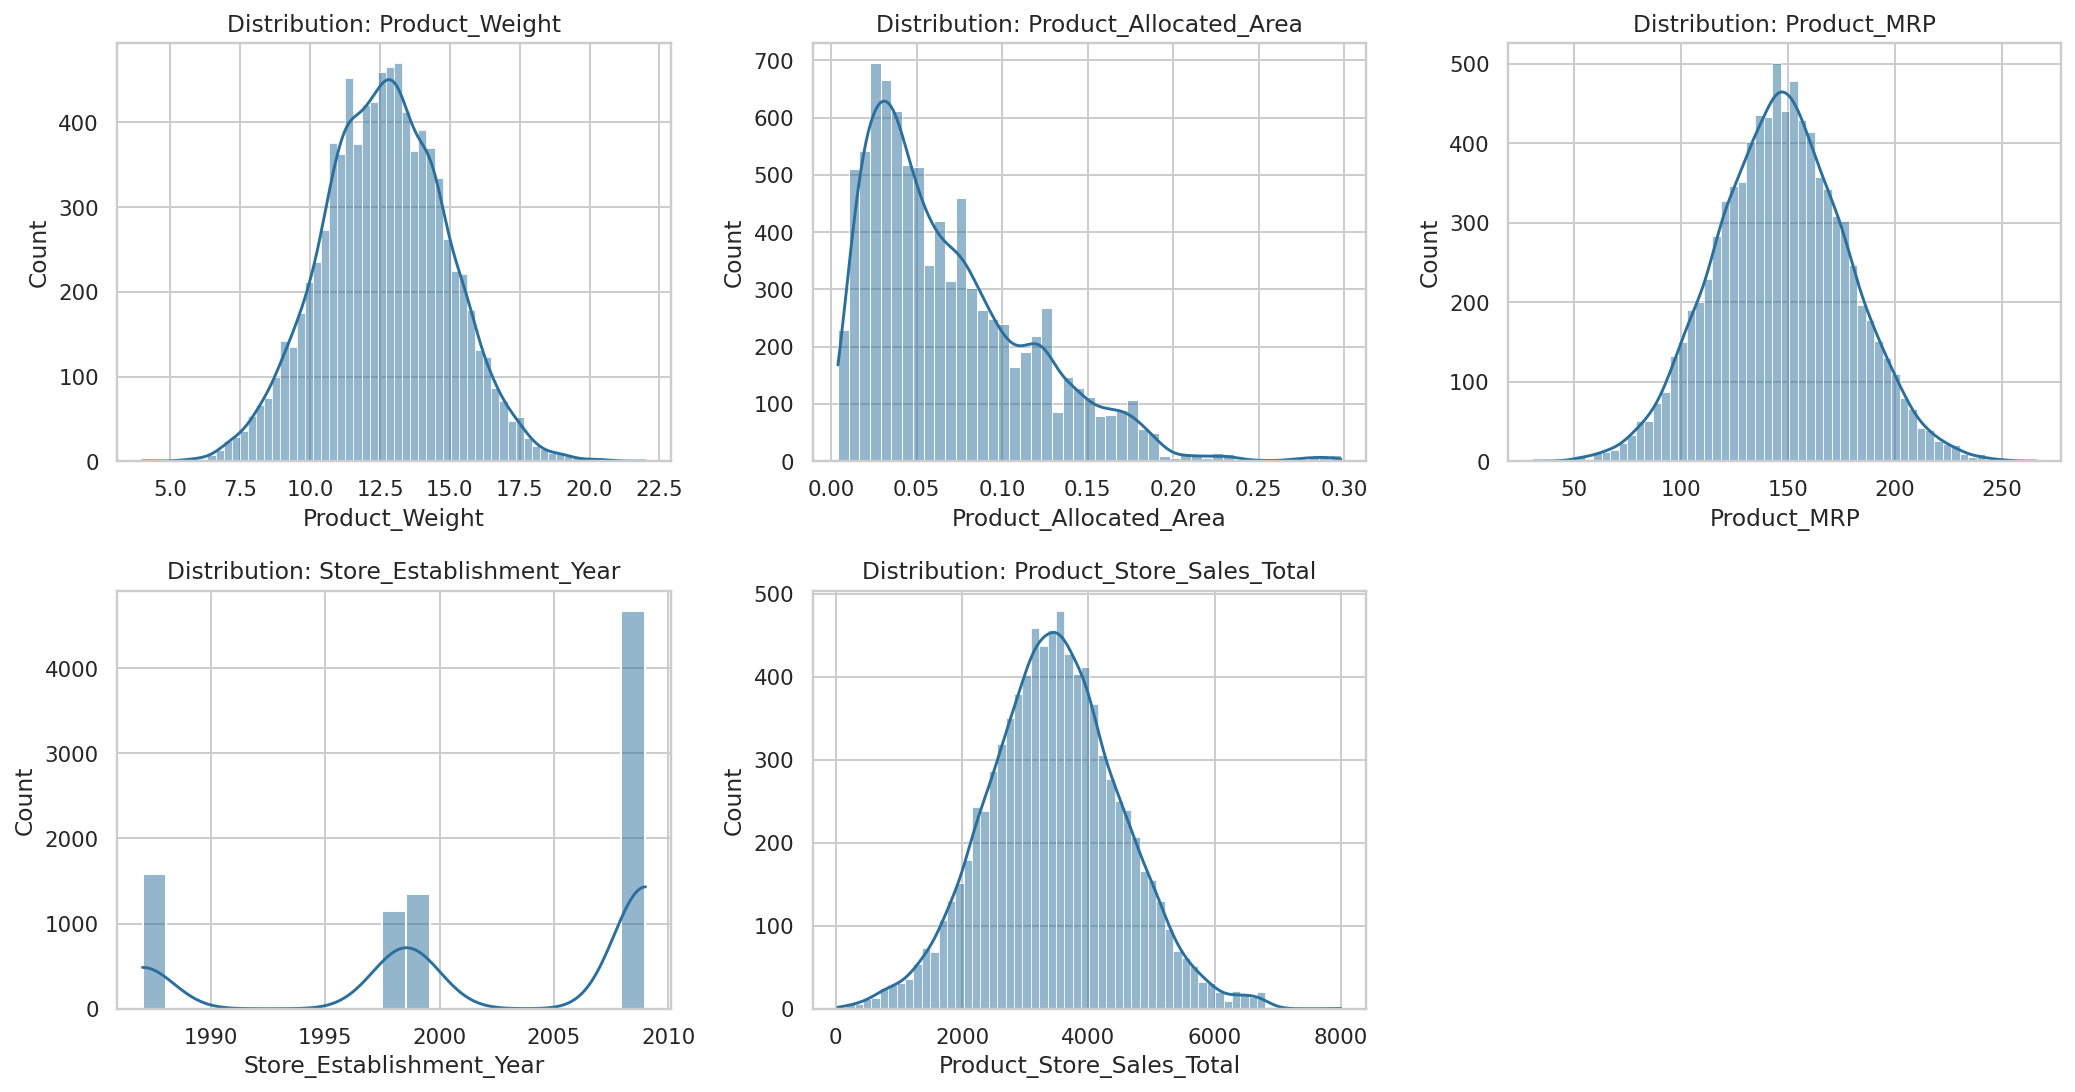

**Distribution readout.** Sales have mean 3,464.00, median 3,452.34, and skew 0.092, indicating a nearly symmetric target here. The IQR check still identifies extremes without assuming that a symmetric distribution has no unusual values. Product MRP spans 31.00 to 266.00.


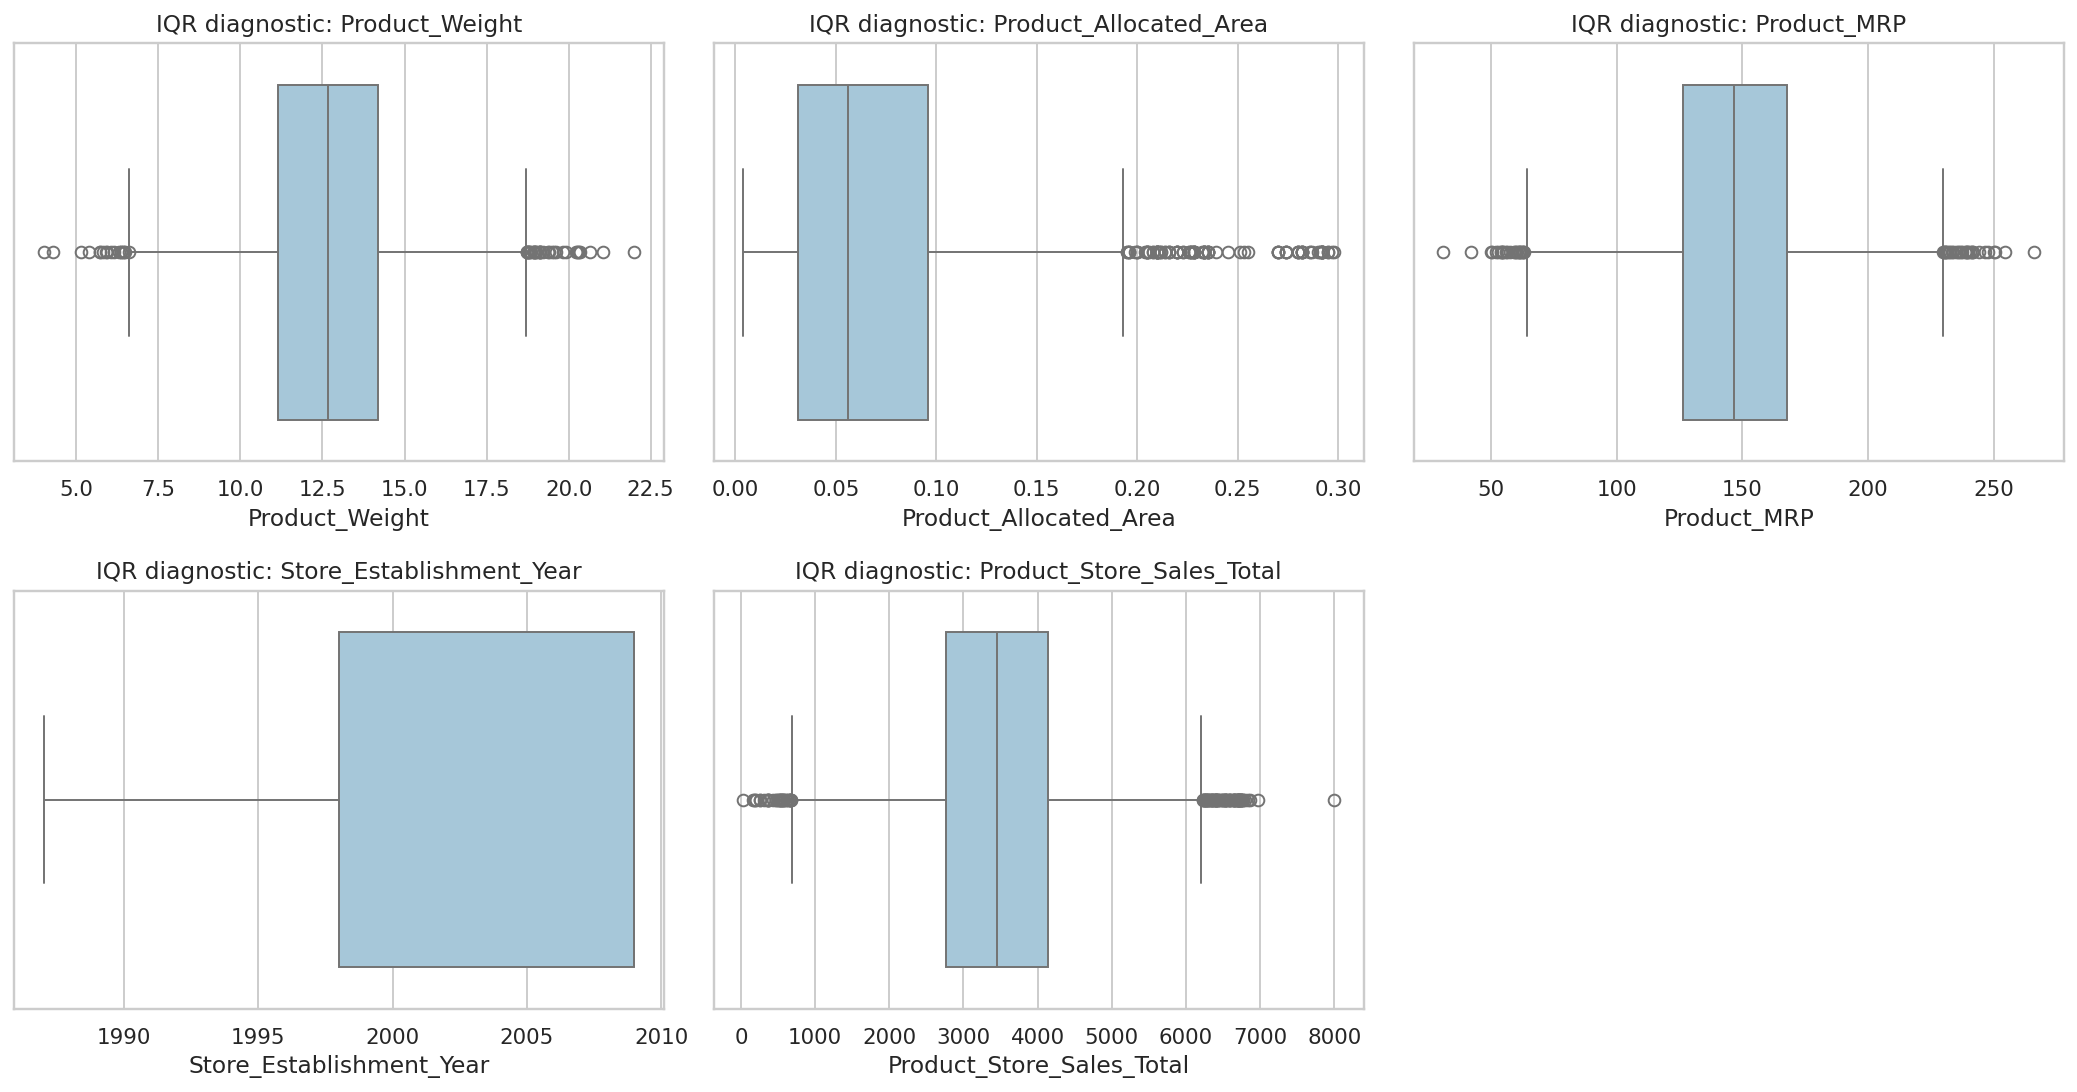


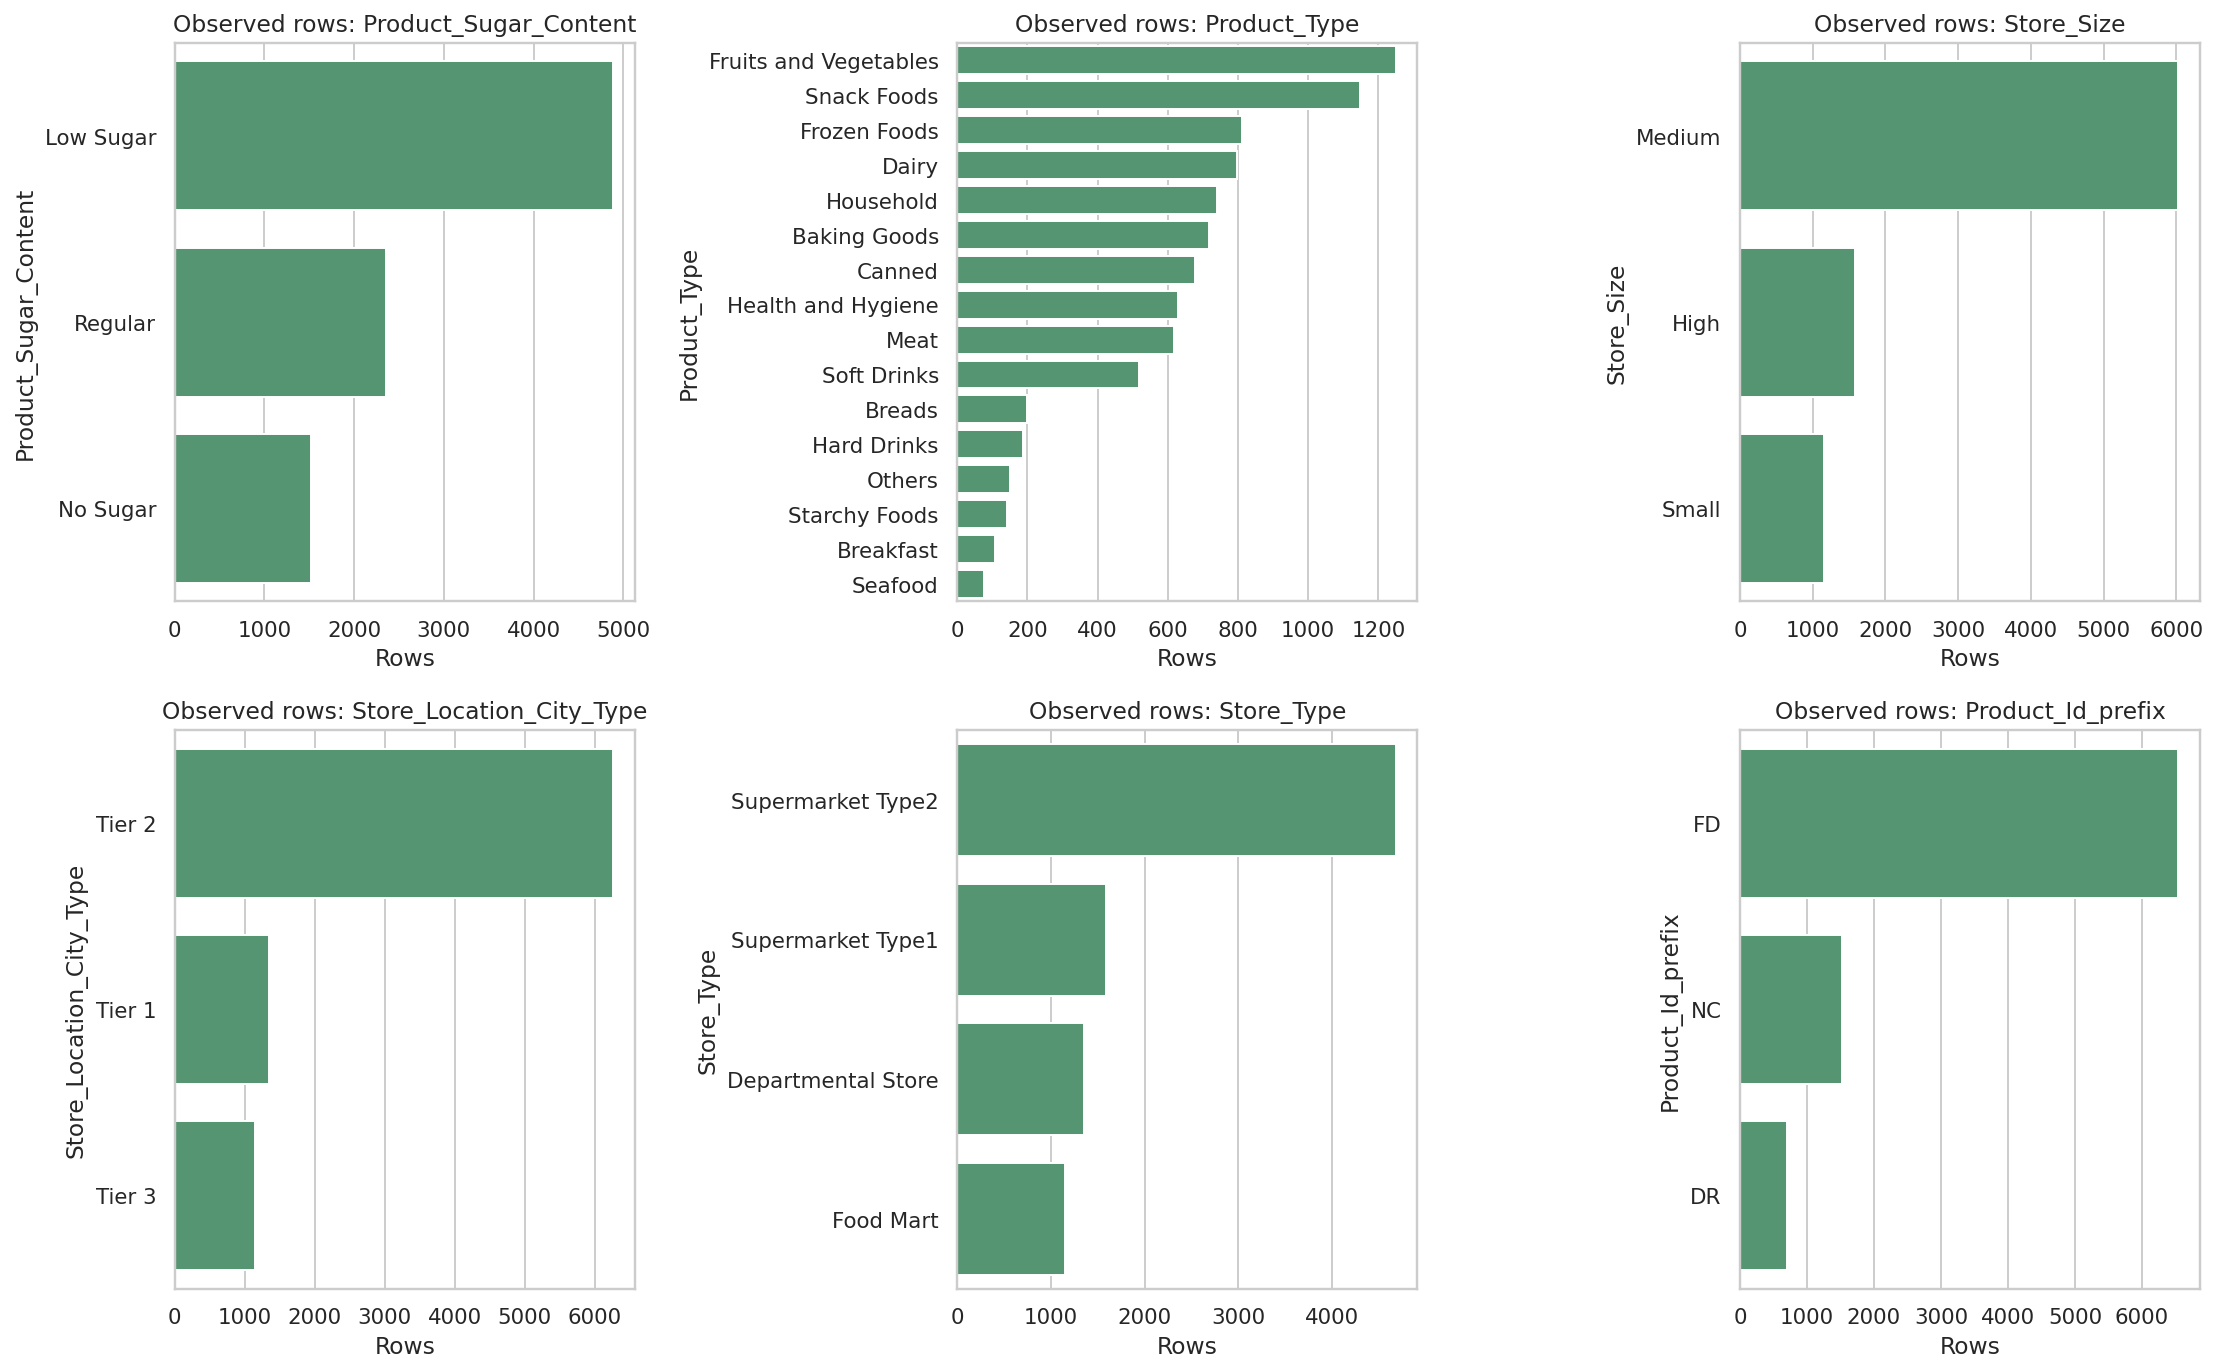

**Category-count readout.** The largest product category is Fruits and Vegetables (n=1,249); the smallest is Seafood (n=76). Unequal group sizes make raw averages descriptive rather than controlled comparisons.

,dimension,category,rows,mean_sales,median_sales
0,Product_Type,Baking Goods,716.0,3425.96,3377.72
1,Product_Type,Breads,200.0,3574.71,3486.95
2,Product_Type,Breakfast,106.0,3416.32,3468.50
3,Product_Type,Canned,677.0,3397.46,3381.60
4,Product_Type,Dairy,796.0,3532.56,3536.28
5,Product_Type,Frozen Foods,811.0,3464.83,3458.09
6,Product_Type,Fruits and Vegetables,1249.0,3443.42,3440.90
7,Product_Type,Hard Drinks,186.0,3364.59,3337.97
8,Product_Type,Health and Hygiene,628.0,3445.39,3449.28
9,Product_Type,Household,740.0,3465.87,3472.35



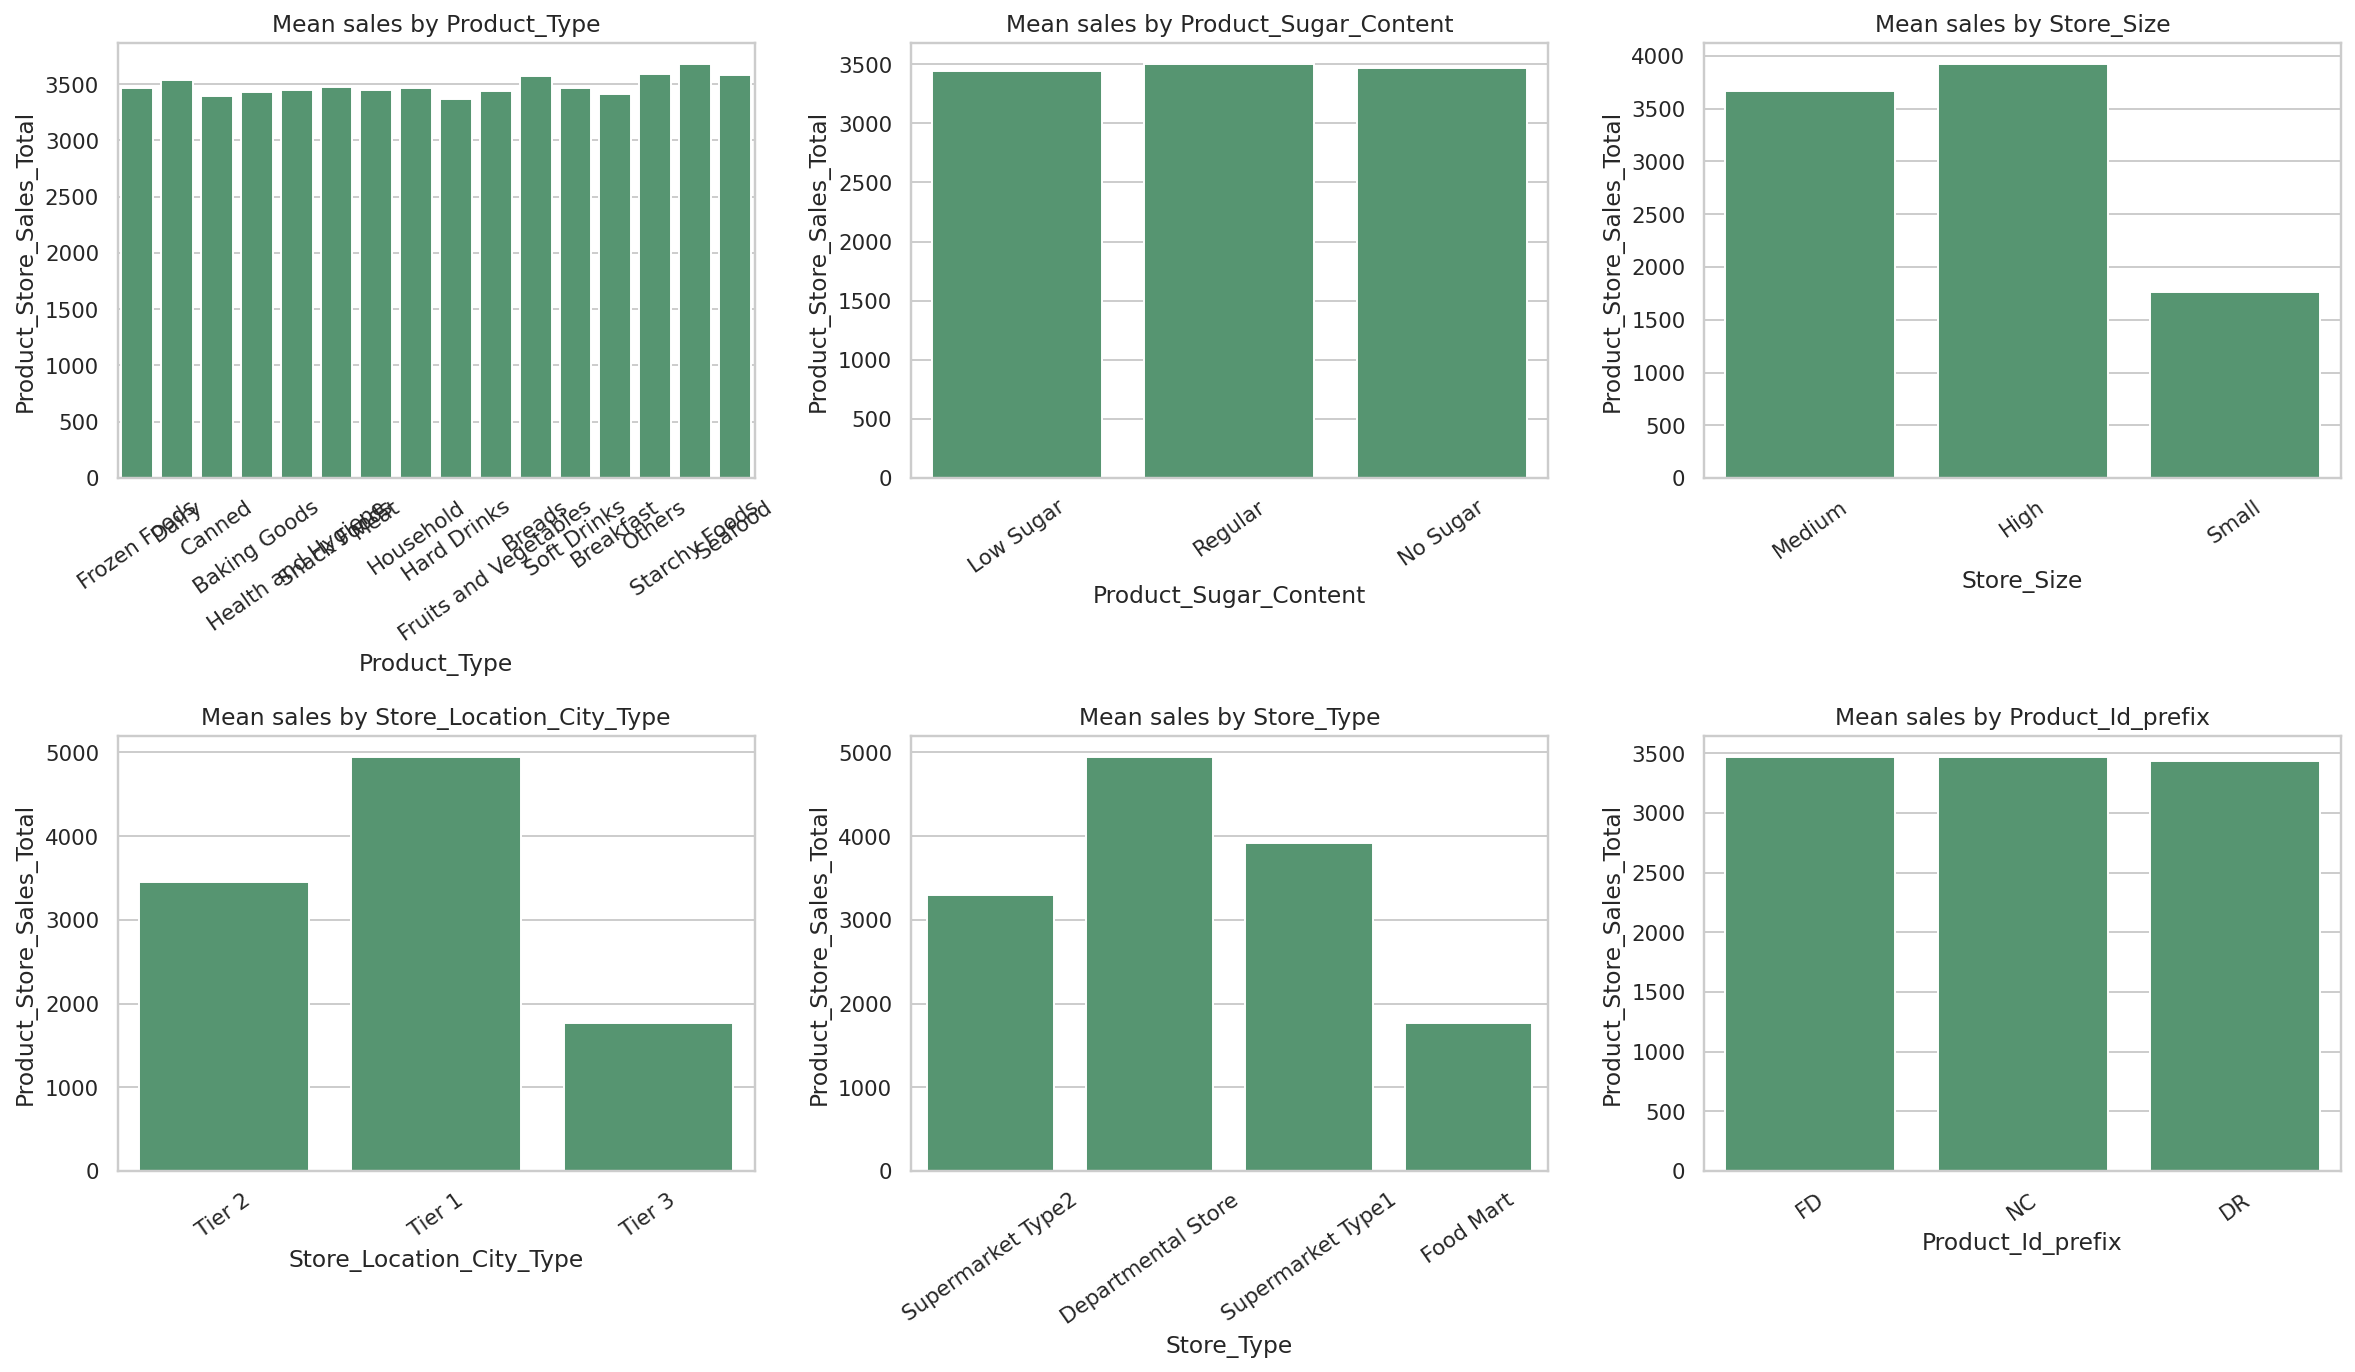

**Group-sales readout.** The highest observed product-type mean is Starchy Foods (3,679.25; n=141); the highest store-type mean is Departmental Store (4,946.97; n=1,349). These summaries reflect product and outlet mix and should not be interpreted as causal effects.

,rows,total_sales,mean_sales
Store_Id,,,
OUT004,4676,15427583.43,3299.31
OUT003,1349,6673457.57,4946.97
OUT001,1586,6223113.18,3923.78
OUT002,1152,2030909.72,1762.94


**Store-level readout.** Store identifiers have fixed values for the four checked profile fields (4 stores). The top three stores contribute 93.3% of sales in this snapshot. This is descriptive sample revenue, not a forecast or a store-level causal effect.


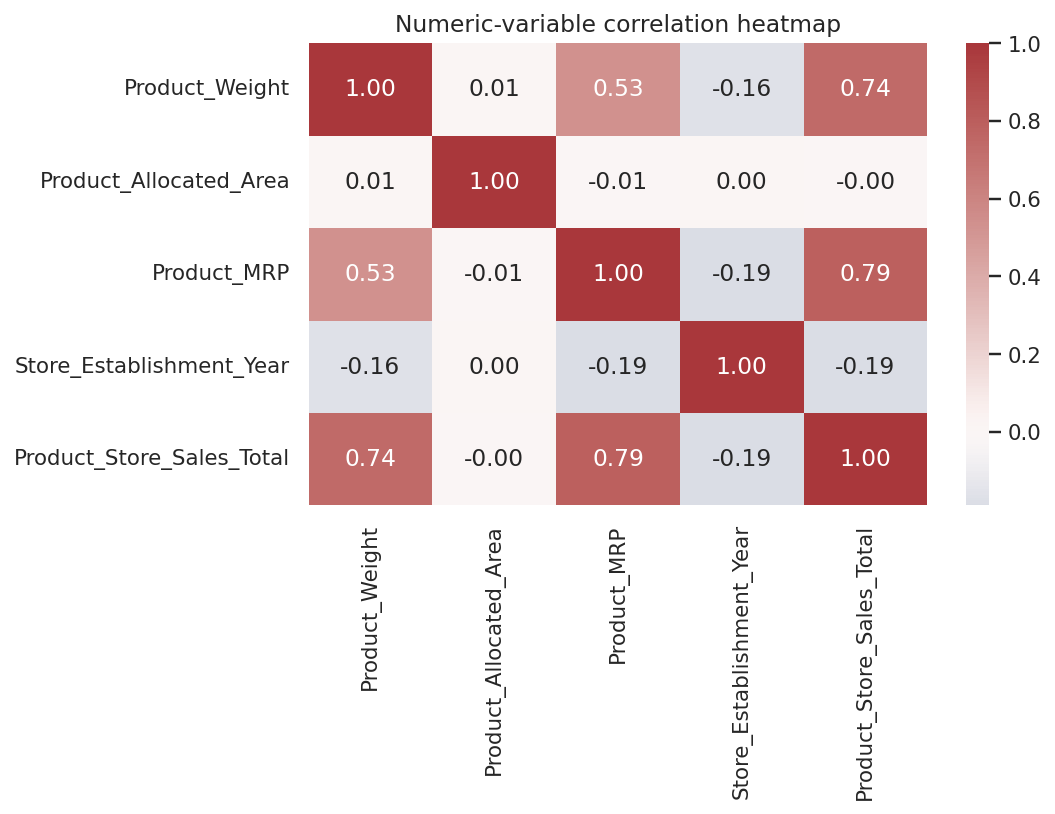

,correlation_with_sales
Product_MRP,0.788
Product_Weight,0.738
Store_Establishment_Year,-0.185
Product_Allocated_Area,-0.001


**Relationship readout.** Product MRP has the strongest numeric association with sales (r=0.788); this is association, not proof that price changes cause the observed revenue differences. Store attributes are repeated across products for each store identifier, so their effects cannot be separated cleanly from outlet identity in this dataset.

In [3]:
# Inspect numeric distributions before modeling.
numeric_columns = [
    'Product_Weight', 'Product_Allocated_Area', 'Product_MRP',
    'Store_Establishment_Year', TARGET,
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, column in zip(axes.flat, numeric_columns):
    sns.histplot(data=df, x=column, kde=True, ax=axis, color='#2b6f9c')
    axis.set_title(f'Distribution: {column}')
for axis in axes.flat[len(numeric_columns):]:
    axis.set_visible(False)
fig.tight_layout()
show_figure(fig, alt_text='Histograms of product weight, allocated area, price, establishment year, and sales.')
display(Markdown(
    f"**Distribution readout.** Sales have mean {df[TARGET].mean():,.2f}, median "
    f"{df[TARGET].median():,.2f}, and skew {df[TARGET].skew():.3f}, indicating a nearly symmetric target here. "
    "The IQR check still identifies extremes without assuming that a symmetric distribution has no unusual values. Product MRP spans "
    f"{df['Product_MRP'].min():,.2f} to {df['Product_MRP'].max():,.2f}."
))

box_columns = numeric_columns
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, column in zip(axes.flat, box_columns):
    sns.boxplot(data=df, x=column, ax=axis, color='#9ecae1')
    axis.set_title(f'IQR diagnostic: {column}')
for axis in axes.flat[len(box_columns):]:
    axis.set_visible(False)
fig.tight_layout()
show_figure(fig, alt_text='Separate-scale boxplots for the four numeric inputs and sales target.')

eda_view = df.assign(
    Product_Id_prefix=df['Product_Id'].astype(str).str[:2],
    Product_Sugar_Content=df['Product_Sugar_Content'].replace({'reg': 'Regular'}),
)
categorical_eda_columns = [
    'Product_Sugar_Content', 'Product_Type', 'Store_Size',
    'Store_Location_City_Type', 'Store_Type', 'Product_Id_prefix',
]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for axis, column in zip(axes.flat, categorical_eda_columns):
    order = eda_view[column].value_counts().index
    sns.countplot(data=eda_view, y=column, order=order, ax=axis, color='#4c9f70')
    axis.set_title(f'Observed rows: {column}')
    axis.set_xlabel('Rows')
fig.tight_layout()
show_figure(fig, alt_text='Category counts for sugar content, product type, store profile, and product prefix.')
largest_product_group = df['Product_Type'].value_counts().idxmax()
smallest_product_group = df['Product_Type'].value_counts().idxmin()
display(Markdown(
    f"**Category-count readout.** The largest product category is {largest_product_group} "
    f"(n={df['Product_Type'].value_counts().max():,}); the smallest is {smallest_product_group} "
    f"(n={df['Product_Type'].value_counts().min():,}). Unequal group sizes make raw averages "
    "descriptive rather than controlled comparisons."
))

group_columns = [
    'Product_Type', 'Product_Sugar_Content', 'Store_Size',
    'Store_Location_City_Type', 'Store_Type', 'Product_Id_prefix',
]
group_rows = []
for column in group_columns:
    group_data = eda_view if column in {'Product_Sugar_Content', 'Product_Id_prefix'} else df
    summary = group_data.groupby(column, observed=True)[TARGET].agg(rows='size', mean_sales='mean', median_sales='median')
    group_rows.extend(
        {'dimension': column, 'category': str(category), **row.to_dict()}
        for category, row in summary.iterrows()
    )
group_sales = pd.DataFrame(group_rows)
display(group_sales.round(2))
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for axis, column in zip(axes.flat, group_columns):
    group_data = eda_view if column in {'Product_Sugar_Content', 'Product_Id_prefix'} else df
    sns.barplot(data=group_data, x=column, y=TARGET, estimator='mean', errorbar=None, ax=axis, color='#4c9f70')
    axis.tick_params(axis='x', rotation=35)
    axis.set_title(f'Mean sales by {column}')
fig.tight_layout()
show_figure(fig, alt_text='Mean sales compared across product, sugar, store, city-tier, and product-prefix groups.')
top_product_type = group_sales[group_sales['dimension'] == 'Product_Type'].nlargest(1, 'mean_sales').iloc[0]
top_store_type = group_sales[group_sales['dimension'] == 'Store_Type'].nlargest(1, 'mean_sales').iloc[0]
display(Markdown(
    f"**Group-sales readout.** The highest observed product-type mean is {top_product_type['category']} "
    f"({top_product_type['mean_sales']:,.2f}; n={int(top_product_type['rows']):,}); the highest store-type mean is "
    f"{top_store_type['category']} ({top_store_type['mean_sales']:,.2f}; n={int(top_store_type['rows']):,}). "
    "These summaries reflect product and outlet mix and should not be interpreted as causal effects."
))

store_profile_columns = ['Store_Type', 'Store_Size', 'Store_Location_City_Type', 'Store_Establishment_Year']
store_profile_counts = df.groupby('Store_Id')[store_profile_columns].nunique(dropna=False)
assert store_profile_counts.le(1).all().all(), 'At least one store identifier has conflicting store profiles.'
store_sales = (
    df.groupby('Store_Id', observed=True)[TARGET]
      .agg(rows='size', total_sales='sum', mean_sales='mean')
      .sort_values('total_sales', ascending=False)
)
display(store_sales.head(8).round(2))
display(Markdown(
    f"**Store-level readout.** Store identifiers have fixed values for the four checked profile fields "
    f"({store_profile_counts.shape[0]:,} stores). The top three stores contribute "
    f"{store_sales['total_sales'].head(3).sum() / df[TARGET].sum():.1%} of sales in this snapshot. "
    "This is descriptive sample revenue, not a forecast or a store-level causal effect."
))

numeric_correlations = df[numeric_columns].corr()
fig, axis = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric_correlations, annot=True, fmt='.2f', cmap='vlag', center=0, ax=axis)
axis.set_title('Numeric-variable correlation heatmap')
fig.tight_layout()
show_figure(fig, alt_text='Annotated correlation heatmap for numeric product, store, and sales variables.')
display(numeric_correlations[TARGET].drop(TARGET).sort_values(key=lambda values: values.abs(), ascending=False).to_frame('correlation_with_sales').round(3))
display(Markdown(
    f"**Relationship readout.** Product MRP has the strongest numeric association with sales "
    f"(r={numeric_correlations.loc['Product_MRP', TARGET]:.3f}); this is association, not proof that price "
    "changes cause the observed revenue differences. Store attributes are repeated across products for "
    "each store identifier, so their effects cannot be separated cleanly from outlet identity in this dataset."
))

In [4]:
# Calculate observations from this run so the business interpretation stays tied to the supplied data.
eda_rows, eda_columns = df.shape
missing_cells = int(df.isna().sum().sum())
duplicate_rows = int(df.duplicated().sum())
target_values = df[TARGET]
target_skew = float(target_values.skew())
raw_reg_rows = int(df['Product_Sugar_Content'].astype(str).str.strip().str.casefold().eq('reg').sum())
store_count = int(df['Store_Id'].nunique())
target_q1, target_q3 = target_values.quantile([0.25, 0.75])
target_iqr = target_q3 - target_q1
lower_fence = target_q1 - 1.5 * target_iqr
upper_fence = target_q3 + 1.5 * target_iqr
target_iqr_flags = int(((target_values < lower_fence) | (target_values > upper_fence)).sum())

numeric_associations = (
    df.select_dtypes(include='number')
      .corr()[TARGET]
      .drop(TARGET)
      .sort_values(key=lambda values: values.abs(), ascending=False)
      .head(2)
)
store_type_means = (
    df.groupby('Store_Type', observed=True)[TARGET]
      .agg(rows='size', mean_sales='mean')
      .sort_values('mean_sales', ascending=False)
)
highest_store_type = store_type_means.iloc[0]
lowest_store_type = store_type_means.iloc[-1]
association_summary = ', '.join(
    f'`{feature}` (r = {value:.3f})'
    for feature, value in numeric_associations.items()
)

display(Markdown(f'''### EDA observations and business interpretation

- The supplied source has **{eda_rows:,} rows and {eda_columns} columns**, with **{missing_cells:,} missing cells** and **{duplicate_rows:,} exact duplicate rows**. `Product_Id_prefix` is an added EDA feature, not an extra source column. The raw `reg` spelling occurs in {raw_reg_rows:,} rows and is normalized to `Regular`; EDA group summaries combine these labels.
- Product-store sales have a **mean of {target_values.mean():,.2f}** and **median of {target_values.median():,.2f}**, spanning **{target_values.min():,.2f} to {target_values.max():,.2f}**. Skew is **{target_skew:.3f}**, so the target is nearly symmetric in this sample. The 1.5 x IQR diagnostic flags {target_iqr_flags:,} rows; these valid outcomes are not removed solely for being extreme.
- The strongest numeric associations with sales are {association_summary}. These are exploratory correlations, not causal effects.
- Average sales differ across observed store types: **{store_type_means.index[0]}** averages {highest_store_type['mean_sales']:,.2f} across {int(highest_store_type['rows']):,} rows, while **{store_type_means.index[-1]}** averages {lowest_store_type['mean_sales']:,.2f} across {int(lowest_store_type['rows']):,} rows. Store/product mix and unequal group sizes prevent treating this contrast as a causal store-type effect.
- The {store_count} observed stores each have a single, fixed store profile. Store size, city tier, type, and establishment year are therefore confounded with store identity; random row splits do not test performance on an unseen store.
'''))


### EDA observations and business interpretation

- The supplied source has **8,763 rows and 12 columns**, with **0 missing cells** and **0 exact duplicate rows**. `Product_Id_prefix` is an added EDA feature, not an extra source column. The raw `reg` spelling occurs in 108 rows and is normalized to `Regular`; EDA group summaries combine these labels.
- Product-store sales have a **mean of 3,464.00** and **median of 3,452.34**, spanning **33.00 to 8,000.00**. Skew is **0.092**, so the target is nearly symmetric in this sample. The 1.5 x IQR diagnostic flags 119 rows; these valid outcomes are not removed solely for being extreme.
- The strongest numeric associations with sales are `Product_MRP` (r = 0.788), `Product_Weight` (r = 0.738). These are exploratory correlations, not causal effects.
- Average sales differ across observed store types: **Departmental Store** averages 4,946.97 across 1,349 rows, while **Food Mart** averages 1,762.94 across 1,152 rows. Store/product mix and unequal group sizes prevent treating this contrast as a causal store-type effect.
- The 4 observed stores each have a single, fixed store profile. Store size, city tier, type, and establishment year are therefore confounded with store identity; random row splits do not test performance on an unseen store.


## 5. Preprocessing and feature engineering

The prediction contract deliberately excludes `Store_Id` and the full `Product_Id`: both are identifiers and can encourage memorization. The product's two-letter prefix is retained as a coarse group feature. Establishment year becomes store age using the fixed reference year **2025**; a fixed anchor prevents runtime-date drift. Product type is collapsed to a documented perishability grouping so training, single inference, and batch inference share one mapping. `Frozen Foods` is included because it requires cold-chain handling even though it can have a long frozen shelf life; this intentionally differs from the course example that labels FD6114 as `Non Perishables`. The binary label is an operational proxy, not a literal estimate of spoilage. `reg` is normalized to `Regular`.

This broad perishability grouping is an operational simplification rather than a claim about shelf life. Outliers are measured with the 1.5×IQR rule. The tree-based candidates do not require scaling; valid high sales are not clipped or deleted solely because they exceed an IQR fence.

In [5]:
# Reuse the same feature builder used by the inference API.
engineered = engineer_raw_dataframe(df)
y = df[TARGET].astype(float).copy()
X = engineered.loc[:, MODEL_FEATURES].copy()
assert list(X.columns) == list(MODEL_FEATURES)
assert len(X) == len(y)
print('Engineered feature matrix:', X.shape)
display(X.head())
print('Normalized sugar labels:', X['Product_Sugar_Content'].value_counts().to_dict())

outlier_rows = []
for column in numeric_columns:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        'feature': column,
        'lower_IQR_fence': lower,
        'upper_IQR_fence': upper,
        'flagged_rows': int(((df[column] < lower) | (df[column] > upper)).sum()),
        'treatment': 'Retained; valid observations and tree models; review residuals',
    })
display(pd.DataFrame(outlier_rows).round(3))

Engineered feature matrix: (8763, 10)


,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Id_char,Store_Age_Years,Product_Type_Category
0,12.66,Low Sugar,0.027,117.08,Medium,Tier 2,Supermarket Type2,FD,16,Perishables
1,16.54,Low Sugar,0.144,171.43,Medium,Tier 1,Departmental Store,FD,26,Perishables
2,14.28,Regular,0.031,162.08,High,Tier 2,Supermarket Type1,FD,38,Non Perishables
3,12.10,Low Sugar,0.112,186.31,High,Tier 2,Supermarket Type1,FD,38,Non Perishables
4,9.57,No Sugar,0.010,123.67,Small,Tier 3,Food Mart,NC,27,Non Perishables


Normalized sugar labels: {'Low Sugar': 4885, 'Regular': 2359, 'No Sugar': 1519}


,feature,lower_IQR_fence,upper_IQR_fence,flagged_rows,treatment
0,Product_Weight,6.605,18.725,54,Retained; valid observations and tree models; ...
1,Product_Allocated_Area,-0.066,0.194,104,Retained; valid observations and tree models; ...
2,Product_MRP,64.022,229.723,57,Retained; valid observations and tree models; ...
3,Store_Establishment_Year,1981.500,2025.500,0,Retained; valid observations and tree models; ...
4,Product_Store_Sales_Total,686.540,6220.340,119,Retained; valid observations and tree models; ...


## 6. Split and leakage-safe preprocessing pipeline

A fixed random 80/20 holdout is created before model fitting. This conventional split leaves roughly 1,750 untouched test rows while retaining ample training examples; a fixed seed makes the comparison reproducible. The source has no dates, so a time-based holdout is not possible. Cross-validation and hyperparameter search use training data only. Numeric features are passed through; categorical features are one-hot encoded inside the pipeline, so each fold learns its own encoding. The encoder's `handle_unknown='ignore'` prevents a fold failure if a rare category is absent from a training fold; the API separately validates and rejects categories outside the supported inference contract.

In [6]:
# Hold out untouched rows before fitting preprocessing or models.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

category_coverage = pd.DataFrame([
    {
        'feature': column,
        'full_data_categories': X[column].nunique(),
        'training_categories': X_train[column].nunique(),
        'test_categories_missing_from_train': len(set(X_test[column]) - set(X_train[column])),
    }
    for column in CATEGORICAL_FEATURES
])
assert (category_coverage['test_categories_missing_from_train'] == 0).all(), 'A test category is absent from training.'
display(category_coverage)
display(Markdown(
    f"All {len(CATEGORICAL_FEATURES)} categorical model inputs retain their observed test categories in the training split. "
    "The encoder's unknown-category handling is therefore a fold/inference safeguard, not a replacement for the explicit API validation."
))

cv = KFold(n_splits=5, shuffle=True, random_state=42)
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('numeric', 'passthrough', list(NUMERIC_FEATURES)),
            ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), list(CATEGORICAL_FEATURES)),
        ],
        remainder='drop',
        verbose_feature_names_out=False,
    )

def make_pipeline(estimator):
    return Pipeline([('preprocessor', make_preprocessor()), ('model', estimator)])

def regression_metrics(actual, predicted, n_features=None):
    metrics = {
        'RMSE': float(np.sqrt(mean_squared_error(actual, predicted))),
        'MAE': float(mean_absolute_error(actual, predicted)),
        'R2': float(r2_score(actual, predicted)),
        'MAPE_percent': float(mean_absolute_percentage_error(actual, predicted) * 100),
    }
    if n_features is not None:
        n_rows = len(actual)
        metrics['Adjusted_R2_approx'] = (
            float(1 - (1 - metrics['R2']) * (n_rows - 1) / (n_rows - n_features - 1))
            if n_rows > n_features + 1 else np.nan
        )
    return metrics

print(f'Train rows: {len(X_train):,}; test rows: {len(X_test):,}; holdout fraction: {len(X_test) / len(X):.2%}')
print(f'CV folds: {cv.n_splits}; selection metric: RMSE (lower is better)')

,feature,full_data_categories,training_categories,test_categories_missing_from_train
0,Product_Sugar_Content,3,3,0
1,Store_Size,3,3,0
2,Store_Location_City_Type,3,3,0
3,Store_Type,4,4,0
4,Product_Id_char,3,3,0
5,Product_Type_Category,2,2,0


All 6 categorical model inputs retain their observed test categories in the training split. The encoder's unknown-category handling is therefore a fold/inference safeguard, not a replacement for the explicit API validation.

Train rows: 7,010; test rows: 1,753; holdout fraction: 20.00%
CV folds: 5; selection metric: RMSE (lower is better)


## 7. Model building and initial comparison

The mean DummyRegressor is a baseline. Random Forest and Gradient Boosting are two permitted assignment models. Each includes the same preprocessing pipeline and is evaluated on identical five-fold splits. RMSE is the selection metric; MAE, R², and MAPE add complementary validation evidence. Mean training-fold versus validation-fold errors provide an initial overfit diagnostic.

In [7]:
estimators = {
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

# Compare candidates on identical training folds with train and validation metrics.
CV_SCORING = {
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2',
    'MAPE_percent': 'neg_mean_absolute_percentage_error',
}
def summarize_cv(model_name, scores):
    row = {'model': model_name}
    for metric in ('RMSE', 'MAE', 'MAPE_percent'):
        scale = 100 if metric == 'MAPE_percent' else 1
        row[f'Train_{metric}_mean'] = float(-scores[f'train_{metric}'].mean() * scale)
        row[f'CV_{metric}_mean'] = float(-scores[f'test_{metric}'].mean() * scale)
        row[f'CV_{metric}_std'] = float(scores[f'test_{metric}'].std(ddof=1) * scale)
    row['Train_R2_mean'] = float(scores['train_R2'].mean())
    row['CV_R2_mean'] = float(scores['test_R2'].mean())
    return row
baseline = make_pipeline(DummyRegressor(strategy='mean'))
baseline_cv = cross_validate(
    baseline, X_train, y_train, scoring=CV_SCORING,
    cv=cv, n_jobs=2, return_train_score=True,
)
initial_rows = [summarize_cv('Mean baseline', baseline_cv)]
for name, estimator in estimators.items():
    pipeline = make_pipeline(estimator)
    scores = cross_validate(
        pipeline, X_train, y_train, scoring=CV_SCORING,
        cv=cv, n_jobs=2, return_train_score=True,
    )
    initial_rows.append(summarize_cv(name, scores))
initial_comparison = pd.DataFrame(initial_rows).sort_values('CV_RMSE_mean')
display(initial_comparison.round(3))
initial_candidates = initial_comparison[initial_comparison['model'] != 'Mean baseline'].sort_values('CV_RMSE_mean')
initial_winner = initial_candidates.iloc[0]
initial_runner_up = initial_candidates.iloc[1]
mean_baseline_rmse = float(initial_comparison.loc[initial_comparison['model'] == 'Mean baseline', 'CV_RMSE_mean'].iloc[0])
baseline_gain_percent = 100 * (mean_baseline_rmse - initial_winner['CV_RMSE_mean']) / mean_baseline_rmse
winner_train_rmse = float(initial_winner['Train_RMSE_mean'])
winner_cv_gap = float(initial_winner['CV_RMSE_mean'] - winner_train_rmse)
display(Markdown(
    f"Across the same {cv.n_splits} training folds, **{initial_winner['model']}** has the lowest initial mean CV RMSE "
    f"({initial_winner['CV_RMSE_mean']:,.2f}; fold SD {initial_winner['CV_RMSE_std']:,.2f}), ahead of "
    f"{initial_runner_up['model']} ({initial_runner_up['CV_RMSE_mean']:,.2f}). The selected candidate improves "
    f"RMSE by {baseline_gain_percent:.1f}% relative to the mean baseline ({mean_baseline_rmse:,.2f}). "
    f"Its mean training-fold RMSE is {winner_train_rmse:,.2f}, a {winner_cv_gap:,.2f} train-to-validation gap. "
    "These are training-fold comparisons, not held-out test results."
))

,model,Train_RMSE_mean,CV_RMSE_mean,CV_RMSE_std,Train_MAE_mean,CV_MAE_mean,CV_MAE_std,Train_MAPE_percent_mean,CV_MAPE_percent_mean,CV_MAPE_percent_std,Train_R2_mean,CV_R2_mean
1,Random Forest,108.741,286.939,30.770,40.991,108.497,9.707,1.520,4.221,0.540,0.990,0.927
2,Gradient Boosting,291.297,315.009,32.986,135.764,146.683,10.156,5.077,6.325,1.572,0.925,0.912
0,Mean baseline,1064.889,1065.019,14.073,839.890,839.998,11.338,34.043,34.043,2.981,0.000,-0.001


Across the same 5 training folds, **Random Forest** has the lowest initial mean CV RMSE (286.94; fold SD 30.77), ahead of Gradient Boosting (315.01). The selected candidate improves RMSE by 73.1% relative to the mean baseline (1,065.02). Its mean training-fold RMSE is 108.74, a 178.20 train-to-validation gap. These are training-fold comparisons, not held-out test results.

## 8. Hyperparameter tuning

RandomizedSearchCV samples 18 configurations per model from broad candidate ranges, using five-fold CV on training data only. `n_estimators` controls ensemble size; `max_depth` limits interaction complexity; `min_samples_leaf` regularizes small leaves; `max_features` controls Random Forest split diversity; and Gradient Boosting's `learning_rate` scales each sequential correction, trading step size against the number of boosting stages. If a selected numeric value remains at an edge, the result is reported as a search limitation, not a proven optimum. RMSE is minimized, and the untouched holdout does not participate in tuning.

In [8]:
# Keep the randomized search bounded and confined to training-fold CV.
parameter_spaces = {
    'Random Forest': {
        'model__n_estimators': [250, 400, 600, 900],
        'model__max_depth': [None, 12, 20, 32, 48],
        'model__min_samples_leaf': [1, 2, 4, 8],
        'model__max_features': ['sqrt', 0.5, 0.75, 1.0],
    },
    'Gradient Boosting': {
        'model__n_estimators': [100, 200, 350, 500],
        'model__learning_rate': [0.01, 0.03, 0.05, 0.08, 0.12, 0.2],
        'model__max_depth': [2, 3, 4, 5, 6],
        'model__min_samples_leaf': [1, 2, 4, 8],
    },
}

tuned_searches = {}
tuning_rows = []
for name, estimator in estimators.items():
    search = RandomizedSearchCV(
        estimator=make_pipeline(estimator),
        param_distributions=parameter_spaces[name],
        n_iter=18,
        scoring='neg_root_mean_squared_error',
        cv=cv,
        random_state=42,
        n_jobs=1,
        refit=True,
        return_train_score=True,
        error_score='raise',
    )
    started = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - started
    tuned_searches[name] = search
    tuning_rows.append({
        'model': name,
        'best_train_RMSE': float(-search.cv_results_['mean_train_score'][search.best_index_]),
        'best_CV_RMSE': float(-search.best_score_),
        'CV_minus_train_RMSE': float(search.cv_results_['mean_train_score'][search.best_index_] - search.cv_results_['mean_test_score'][search.best_index_]),
        'search_seconds': elapsed,
    })
tuning_results = pd.DataFrame(tuning_rows).sort_values('best_CV_RMSE')
display(tuning_results.round(3))
for name, search in tuned_searches.items():
    parameter_lines = '\n'.join(f"- `{key}`: `{value}`" for key, value in sorted(search.best_params_.items()))
    display(Markdown(f"**{name} selected parameters**\n\n{parameter_lines}"))
boundary_rows = []
for model_name, fitted_search in tuned_searches.items():
    numeric_edges = []
    for parameter, candidates in parameter_spaces[model_name].items():
        numeric_candidates = [value for value in candidates if isinstance(value, (int, float))]
        if len(numeric_candidates) >= 2 and fitted_search.best_params_[parameter] in {min(numeric_candidates), max(numeric_candidates)}:
            numeric_edges.append(f"{parameter}={fitted_search.best_params_[parameter]}")
    boundary_rows.append({'model': model_name, 'selected_numeric_edges': ', '.join(numeric_edges) or 'None'})
display(pd.DataFrame(boundary_rows))
boundary_limits = [f"{row['model']}: {row['selected_numeric_edges']}" for row in boundary_rows if row['selected_numeric_edges'] != 'None']
if boundary_limits:
    display(Markdown('**Search-range limitation:** selected values at numeric edges are ' + '; '.join(boundary_limits) + '. These candidates need further range testing; they are not established optima.'))
else:
    display(Markdown('No selected numeric hyperparameter was at a search boundary in these sampled configurations. This randomized search still does not establish a global optimum.'))
initial_rmse_by_model = initial_comparison.set_index('model')['CV_RMSE_mean']
tuning_comments = []
for _, tuned_row in tuning_results.iterrows():
    before_rmse = float(initial_rmse_by_model[tuned_row['model']])
    gain = before_rmse - float(tuned_row['best_CV_RMSE'])
    gain_percent = 100 * gain / before_rmse
    change_label = 'lower' if gain >= 0 else 'higher'
    tuning_comments.append(
        f"- **{tuned_row['model']}**: CV RMSE changed from {before_rmse:,.2f} to "
        f"{tuned_row['best_CV_RMSE']:,.2f} ({abs(gain):,.2f} {change_label}, {abs(gain_percent):.1f}%; "
        f"search time {tuned_row['search_seconds']:.1f} s)."
    )
best_tuned_row = tuning_results.iloc[0]
second_tuned_row = tuning_results.iloc[1]
display(Markdown(
    "Observed tuning results relative to the untuned training-fold baselines:\n\n"
    + "\n".join(tuning_comments)
    + f"\n\nThe best tuned CV result is **{best_tuned_row['model']}** at {best_tuned_row['best_CV_RMSE']:,.2f}, "
    + f"{float(second_tuned_row['best_CV_RMSE']) - float(best_tuned_row['best_CV_RMSE']):,.2f} RMSE below "
    + f"{second_tuned_row['model']}. Each search sampled 18 settings from broad ranges with {cv.n_splits}-fold CV; this bounded randomized search does not establish a global optimum."
))

,model,best_train_RMSE,best_CV_RMSE,CV_minus_train_RMSE,search_seconds
0,Random Forest,172.426,281.097,108.670,608.863
1,Gradient Boosting,249.340,288.859,39.519,294.178


**Random Forest selected parameters**

- `model__max_depth`: `20`
- `model__max_features`: `0.75`
- `model__min_samples_leaf`: `2`
- `model__n_estimators`: `900`

**Gradient Boosting selected parameters**

- `model__learning_rate`: `0.01`
- `model__max_depth`: `5`
- `model__min_samples_leaf`: `2`
- `model__n_estimators`: `500`

,model,selected_numeric_edges
0,Random Forest,model__n_estimators=900
1,Gradient Boosting,"model__n_estimators=500, model__learning_rate=..."


**Search-range limitation:** selected values at numeric edges are Random Forest: model__n_estimators=900; Gradient Boosting: model__n_estimators=500, model__learning_rate=0.01. These candidates need further range testing; they are not established optima.

Observed tuning results relative to the untuned training-fold baselines:

- **Random Forest**: CV RMSE changed from 286.94 to 281.10 (5.84 lower, 2.0%; search time 608.9 s).
- **Gradient Boosting**: CV RMSE changed from 315.01 to 288.86 (26.15 lower, 8.3%; search time 294.2 s).

The best tuned CV result is **Random Forest** at 281.10, 7.76 RMSE below Gradient Boosting. Each search sampled 18 settings from broad ranges with 5-fold CV; this bounded randomized search does not establish a global optimum.

## 9. Final model selection, test evaluation, and error analysis

The model with the lowest tuned mean CV RMSE is selected; test results are reported for both tuned candidates only after the search is fixed. Training-versus-test RMSE helps expose a generalization gap. RMSE and MAE use the original sales units; MAPE is a percentage. Adjusted R² is shown as a feature-count approximation for descriptive comparison only because its classical degrees-of-freedom interpretation is not exact for tree ensembles.

,model,CV_RMSE,encoded_feature_count,train_RMSE,train_MAE,train_R2,train_MAPE_percent,train_Adjusted_R2_approx,test_RMSE,test_MAE,test_R2,test_MAPE_percent,test_Adjusted_R2_approx,test_to_train_RMSE_ratio
0,Random Forest,281.097,22,171.747,60.998,0.974,2.306,0.974,276.667,106.605,0.933,3.875,0.932,1.611
1,Gradient Boosting,288.859,22,252.531,106.357,0.944,3.980,0.944,286.833,124.033,0.928,4.557,0.927,1.136


,model,CV_RMSE,stage
3,Random Forest,281.097,tuned
1,Random Forest,286.939,untuned
4,Gradient Boosting,288.859,tuned
2,Gradient Boosting,315.009,untuned
0,Mean baseline,1065.019,baseline


,selected_model,RMSE,MAE,R2,MAPE_percent,Adjusted_R2_approx
0,Random Forest,276.667,106.605,0.933,3.875,0.932



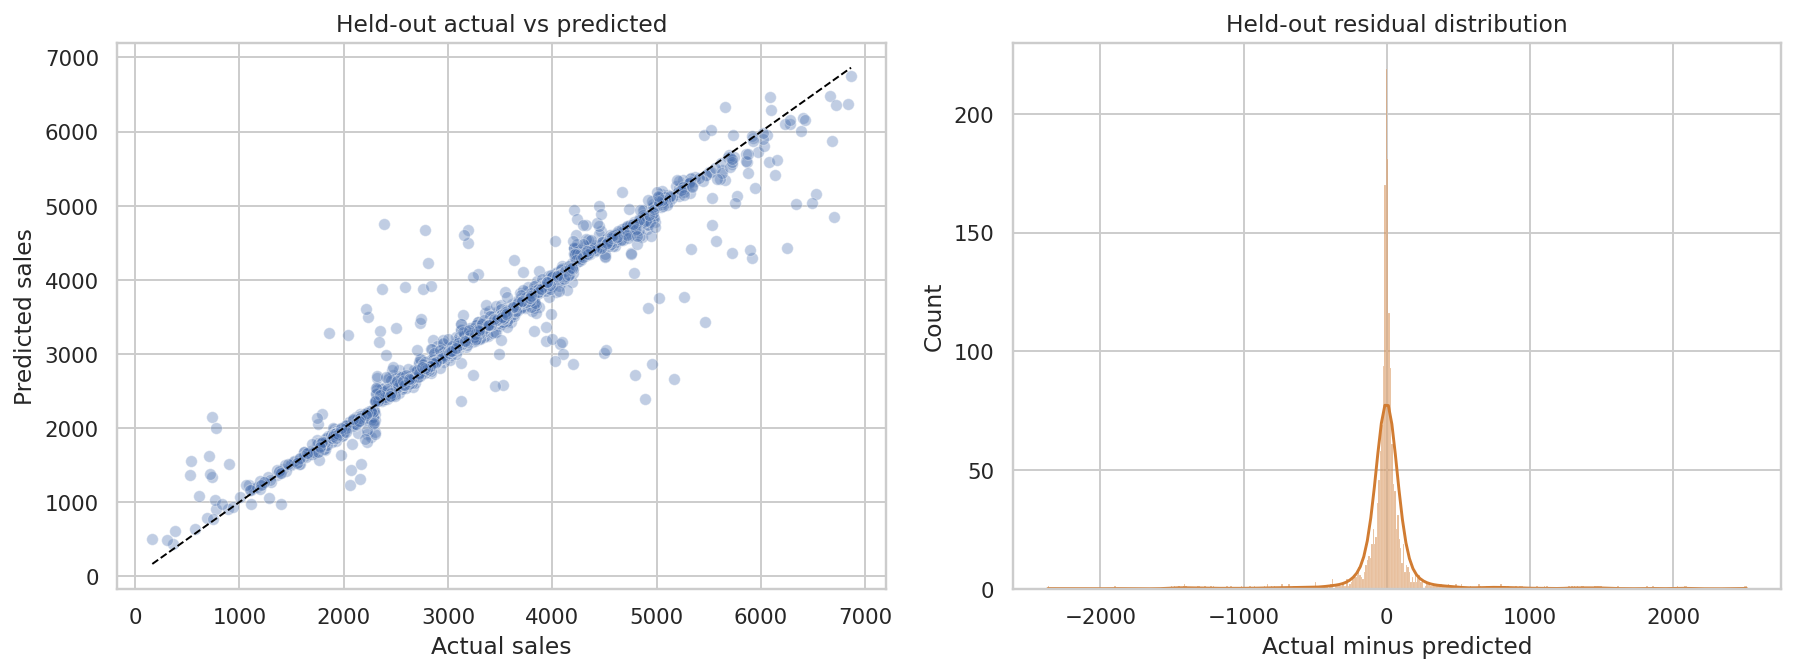

Selected by training CV: Random Forest; held-out test RMSE: 276.67; held-out test MAE: 106.61.


The final choice is **Random Forest** because it has the lowest tuned training CV RMSE (281.10, versus 288.86 for the next tuned model). On the untouched 1,753-row random holdout, RMSE is 276.67, MAE is 106.61, R-squared is 0.933, and MAPE is 3.87%. Test RMSE is 1.6% below the selected CV RMSE. Training RMSE is 171.75; the holdout/train RMSE ratio is 1.61, showing a measurable fit gap. This supports performance on a random split of this dataset, not generalization to new stores or a future quarter; no dates are available for a time-based test.

In [9]:
# Select using training CV before evaluating the held-out test set.
selected_name = max(tuned_searches, key=lambda name: tuned_searches[name].best_score_)
final_model = tuned_searches[selected_name].best_estimator_
candidate_predictions = {}
model_comparison_rows = []
for name, search in tuned_searches.items():
    candidate = search.best_estimator_
    feature_count = len(candidate.named_steps['preprocessor'].get_feature_names_out())
    train_predictions = candidate.predict(X_train)
    heldout_predictions = candidate.predict(X_test)
    candidate_predictions[name] = heldout_predictions
    row = {
        'model': name,
        'CV_RMSE': float(-search.best_score_),
        'encoded_feature_count': feature_count,
    }
    for split_name, actual, predicted in (
        ('train', y_train, train_predictions),
        ('test', y_test, heldout_predictions),
    ):
        for metric, value in regression_metrics(actual, predicted, n_features=feature_count).items():
            row[f'{split_name}_{metric}'] = value
    row['test_to_train_RMSE_ratio'] = row['test_RMSE'] / row['train_RMSE']
    model_comparison_rows.append(row)
model_comparison = pd.DataFrame(model_comparison_rows).sort_values('CV_RMSE')
display(model_comparison.round(3))
test_predictions = candidate_predictions[selected_name]
selected_feature_count = int(model_comparison.set_index('model').loc[selected_name, 'encoded_feature_count'])
test_metrics = regression_metrics(y_test, test_predictions, n_features=selected_feature_count)
cv_leaderboard = pd.DataFrame([
    {'model': 'Mean baseline', 'CV_RMSE': initial_comparison.loc[initial_comparison['model'] == 'Mean baseline', 'CV_RMSE_mean'].iloc[0], 'stage': 'baseline'},
    *[
        {'model': name, 'CV_RMSE': row['CV_RMSE_mean'], 'stage': 'untuned'}
        for name, row in zip(estimators, initial_rows[1:], strict=True)
    ],
    *[
        {'model': name, 'CV_RMSE': -search.best_score_, 'stage': 'tuned'}
        for name, search in tuned_searches.items()
    ],
]).sort_values('CV_RMSE')
display(cv_leaderboard.round(3))
display(pd.DataFrame([{'selected_model': selected_name, **test_metrics}]).round(3))

residuals = y_test.to_numpy() - np.asarray(test_predictions)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=y_test, y=test_predictions, alpha=0.35, ax=axes[0])
limits = [min(y_test.min(), np.min(test_predictions)), max(y_test.max(), np.max(test_predictions))]
axes[0].plot(limits, limits, '--', color='black', linewidth=1)
axes[0].set(xlabel='Actual sales', ylabel='Predicted sales', title='Held-out actual vs predicted')
sns.histplot(residuals, kde=True, ax=axes[1], color='#d17c32')
axes[1].set(xlabel='Actual minus predicted', title='Held-out residual distribution')
fig.tight_layout()
show_figure(fig, alt_text='Held-out actual versus predicted sales and the residual distribution.')

print(f'Selected by training CV: {selected_name}; held-out test RMSE: {test_metrics["RMSE"]:,.2f}; held-out test MAE: {test_metrics["MAE"]:,.2f}.')
selected_cv_rmse = float(-tuned_searches[selected_name].best_score_)
runner_up_cv_rmse = min(
    float(-search.best_score_)
    for name, search in tuned_searches.items()
    if name != selected_name
)
selected_comparison = model_comparison.set_index('model').loc[selected_name]
cv_test_difference_percent = 100 * (test_metrics['RMSE'] - selected_cv_rmse) / selected_cv_rmse
display(Markdown(
    f"The final choice is **{selected_name}** because it has the lowest tuned training CV RMSE "
    f"({selected_cv_rmse:,.2f}, versus {runner_up_cv_rmse:,.2f} for the next tuned model). On the untouched "
    f"{len(y_test):,}-row random holdout, RMSE is {test_metrics['RMSE']:,.2f}, MAE is {test_metrics['MAE']:,.2f}, "
    f"R-squared is {test_metrics['R2']:.3f}, and MAPE is {test_metrics['MAPE_percent']:.2f}%. Test RMSE is "
    f"{abs(cv_test_difference_percent):.1f}% {'below' if cv_test_difference_percent < 0 else 'above'} the selected CV RMSE. "
    f"Training RMSE is {selected_comparison['train_RMSE']:,.2f}; the holdout/train RMSE ratio is "
    f"{selected_comparison['test_to_train_RMSE_ratio']:.2f}, showing a measurable fit gap. "
    "This supports performance on a random split of this dataset, not generalization to new stores or a future quarter; no dates are available for a time-based test."
))

## 10. Model interpretation

Permutation importance measures how much the selected model's held-out RMSE worsens when a feature column is shuffled. This is a model-dependence diagnostic, not a causal effect. The test set is used here for interpretation only; it was not used for tuning or model selection.

,feature,mean_RMSE_increase,std_RMSE_increase
3,Product_MRP,496.429,11.456
5,Store_Location_City_Type,432.484,11.253
0,Product_Weight,378.446,7.953
6,Store_Type,311.585,7.421
4,Store_Size,179.727,5.939
8,Store_Age_Years,34.107,1.513
2,Product_Allocated_Area,3.744,0.577
9,Product_Type_Category,0.512,0.511
1,Product_Sugar_Content,-0.367,0.411
7,Product_Id_char,-0.414,0.169



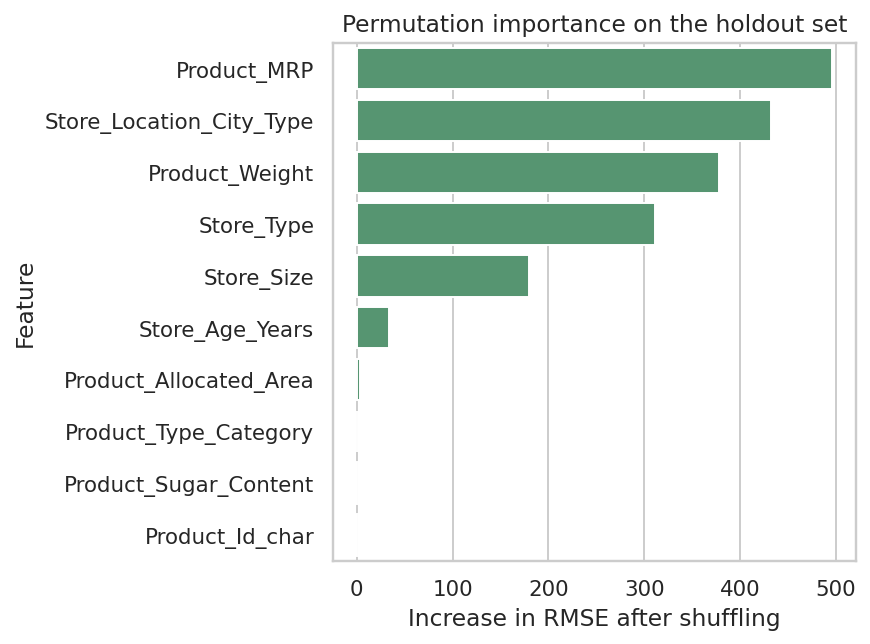

**Interpretation.** Shuffling `Product_MRP` increased held-out RMSE by 496.43 on average (SD 11.46); the next feature, `Store_Location_City_Type`, increased it by 432.48. This ranking is conditional on the fitted model and correlated predictors; it is not a causal ranking or an intervention effect.

In [10]:
importance = permutation_importance(
    final_model, X_test, y_test,
    scoring='neg_root_mean_squared_error',
    n_repeats=5, random_state=42, n_jobs=2,
)
importance_table = pd.DataFrame({
    'feature': X_test.columns,
    'mean_RMSE_increase': importance.importances_mean,
    'std_RMSE_increase': importance.importances_std,
}).sort_values('mean_RMSE_increase', ascending=False)
display(importance_table.round(3))
sns.barplot(data=importance_table.head(10), x='mean_RMSE_increase', y='feature', color='#4c9f70')
plt.title('Permutation importance on the holdout set')
plt.xlabel('Increase in RMSE after shuffling')
plt.ylabel('Feature')
plt.tight_layout()
show_figure(plt.gcf(), alt_text='Top permutation-importance features ranked by increase in holdout RMSE.')
top_importance = importance_table.iloc[0]
next_importance = importance_table.iloc[1]
display(Markdown(
    f"**Interpretation.** Shuffling `{top_importance['feature']}` increased held-out RMSE by "
    f"{top_importance['mean_RMSE_increase']:.2f} on average (SD {top_importance['std_RMSE_increase']:.2f}); "
    f"the next feature, `{next_importance['feature']}`, increased it by {next_importance['mean_RMSE_increase']:.2f}. "
    "This ranking is conditional on the fitted model and correlated predictors; it is not a causal ranking or an intervention effect."
))

## 11. Serialize and verify the complete pipeline

The serialized object includes both the fitted one-hot preprocessing and regressor. It is saved to the path consumed by the Flask service, reloaded, and compared against the same held-out predictions before it is accepted.

In [11]:
BACKEND_DIR = DEPLOYMENT_DIR / 'backend_files'
BACKEND_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = BACKEND_DIR / 'superkart_model.joblib'
# Save preprocessing and estimator together as one inference artifact.
joblib.dump(final_model, MODEL_PATH, compress=3)
reloaded_model = joblib.load(MODEL_PATH)
reloaded_predictions = reloaded_model.predict(X_test)
np.testing.assert_allclose(reloaded_predictions, test_predictions, rtol=1e-12, atol=1e-10)
reloaded_metrics = regression_metrics(y_test, reloaded_predictions)
metadata = {
    'selected_model': selected_name,
    'feature_columns': list(MODEL_FEATURES),
    'target': TARGET,
    'store_age_reference_year': STORE_AGE_REFERENCE_YEAR,
    'training_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'selection_metric': f'{cv.n_splits}-fold training RMSE; lower is better',
    'test_metrics': reloaded_metrics,
}
metadata_path = BACKEND_DIR / 'model_metadata.json'
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print(f'Saved and reloaded complete pipeline: {MODEL_PATH.relative_to(ROOT)} ({MODEL_PATH.stat().st_size:,} bytes)')
print('Reloaded test metrics:', {key: round(value, 3) for key, value in reloaded_metrics.items()})
print(f'Model metadata: {metadata_path.relative_to(ROOT)}')

Saved and reloaded complete pipeline: deployment/backend_files/superkart_model.joblib (72,736,269 bytes)
Reloaded test metrics: {'RMSE': 276.667, 'MAE': 106.605, 'R2': 0.933, 'MAPE_percent': 3.875}
Model metadata: deployment/backend_files/model_metadata.json


## 12. Inference contract and API tests

Training and deployment use the same ten-column feature order. The provided batch includes two rows whose `Store_Type` (`Supermarket Type3`) was never present in the training data. The API rejects those rows individually and retains successful predictions for valid rows; it does not silently turn an unknown category into an apparently supported prediction.

In [12]:
# Direct training-to-inference parity using one supplied raw observation.
sample_raw = df.iloc[0].to_dict()
raw_payload = {field: sample_raw[field] for field in RAW_FEATURES}
engineered_payload = engineer_raw_record(raw_payload)
training_row = engineer_raw_dataframe(df.iloc[[0]])
assert engineered_payload == training_row.iloc[0].to_dict()
single_estimate = float(reloaded_model.predict(pd.DataFrame([engineered_payload], columns=MODEL_FEATURES))[0])
print('Feature contract parity passed.')
print('Single-row estimated sales:', round(single_estimate, 2))
print('Engineered request fields:', list(engineered_payload))

Feature contract parity passed.
Single-row estimated sales: 2925.31
Engineered request fields: ['Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Product_MRP', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Id_char', 'Store_Age_Years', 'Product_Type_Category']


In [13]:
# Use Flask's in-process test client: no public service or credentials are required.
from backend_files.app import app as flask_app

client = flask_app.test_client()
valid_batch = pd.read_csv(DATA_DIR / 'Batch_Data_SuperKart.csv')
valid_payload = {
    key: (value.item() if hasattr(value, 'item') else value)
    for key, value in valid_batch.iloc[0].to_dict().items()
}
single_response = client.post('/v1/predict', json=valid_payload)
assert single_response.status_code == 200, single_response.get_json()
assert 'Predicted_Product_Store_Sales_Total' in single_response.get_json()

bad_payload = dict(valid_payload, Store_Type='Supermarket Type3')
invalid_response = client.post('/v1/predict', json=bad_payload)
assert invalid_response.status_code == 400

batch_bytes = valid_batch.to_csv(index=False).encode('utf-8')
batch_response = client.post(
    '/v1/predictbatch',
    data={'file': (io.BytesIO(batch_bytes), 'Batch_Data_SuperKart.csv')},
    content_type='multipart/form-data',
)
assert batch_response.status_code == 200, batch_response.get_json()
batch_result = batch_response.get_json()
assert batch_result['rows_received'] == 10
assert batch_result['predicted_count'] == 8
assert [item['row'] for item in batch_result['errors']] == [5, 10]
missing_column_response = client.post(
    '/v1/predictbatch',
    data={'file': (io.BytesIO(b'Product_MRP\n50\n'), 'invalid.csv')},
    content_type='multipart/form-data',
)
assert missing_column_response.status_code == 400

display(pd.DataFrame([
    {'test': 'valid single prediction', 'status': single_response.status_code},
    {'test': 'unknown category rejected', 'status': invalid_response.status_code},
    {'test': 'batch request', 'status': batch_response.status_code},
    {'test': 'missing batch columns rejected', 'status': missing_column_response.status_code},
]))
print({key: batch_result[key] for key in ['rows_received', 'predicted_count', 'error_count']})
display(pd.DataFrame(batch_result['predictions']))
display(pd.DataFrame(batch_result['errors']))

# Render the real Streamlit page and submit its single-item form to a live local API.
ui_server = make_server('127.0.0.1', 0, flask_app)
ui_server_thread = threading.Thread(target=ui_server.serve_forever, daemon=True)
ui_server_thread.start()
streamlit_context_logger = logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context')
werkzeug_logger = logging.getLogger('werkzeug')
previous_log_levels = (streamlit_context_logger.level, werkzeug_logger.level)
streamlit_context_logger.setLevel(logging.ERROR)
werkzeug_logger.setLevel(logging.WARNING)
try:
    with patch.dict(os.environ, {'API_BASE_URL': f'http://127.0.0.1:{ui_server.server_port}'}):
        ui_test = AppTest.from_file(str(DEPLOYMENT_DIR / 'frontend_files' / 'app.py')).run(timeout=60)
        assert not ui_test.exception, [item.message for item in ui_test.exception]
        ui_buttons = [item.label for item in ui_test.button]
        ui_uploaders = [item.label for item in ui_test.get('file_uploader')]
        ui_downloads = [item.label for item in ui_test.get('download_button')]
        assert 'Estimate product-store sales' in ui_buttons
        assert 'Test connection' in ui_buttons
        assert ui_uploaders == ['Choose a CSV file']
        assert 'Download model-ready CSV template' in ui_downloads
        submit_button = next(item for item in ui_test.button if item.label == 'Estimate product-store sales')
        ui_test = submit_button.click().run(timeout=60)
        assert not ui_test.exception, [item.message for item in ui_test.exception]
        assert any(item.label == 'Predicted product-store sales' for item in ui_test.metric)
finally:
    ui_server.shutdown()
    ui_server_thread.join(timeout=10)
    streamlit_context_logger.setLevel(previous_log_levels[0])
    werkzeug_logger.setLevel(previous_log_levels[1])
display(pd.DataFrame([
    {'frontend check': 'Single-item form returned a live model estimate', 'status': 'passed'},
    {'frontend check': 'Batch CSV uploader and model-ready template are present', 'status': 'passed'},
]))

,test,status
0,valid single prediction,200
1,unknown category rejected,400
2,batch request,200
3,missing batch columns rejected,400


{'rows_received': 10, 'predicted_count': 8, 'error_count': 2}


,Predicted_Product_Store_Sales_Total,row
0,3887.17,1
1,2735.07,2
2,3931.89,3
3,1903.75,4
4,4657.63,6
5,2515.94,7
6,2388.74,8
7,4732.38,9


,message,row
0,Unsupported Store_Type: Supermarket Type3.,5
1,Unsupported Store_Type: Supermarket Type3.,10


,frontend check,status
0,Single-item form returned a live model estimate,passed
1,Batch CSV uploader and model-ready template ar...,passed


## 13. EDA-derived insights and recommendations

The following summaries are computed from the supplied rows. Differences between groups are not interpreted as causal because the data do not control for all commercial factors. Use the model as a planning aid and validate recommendations in a pilot against later actual sales.

In [14]:
product_group_sales = (
    df.assign(Product_Type_Category=engineered['Product_Type_Category'])
      .groupby('Product_Type_Category', observed=True)[TARGET]
      .agg(rows='size', mean_sales='mean', median_sales='median')
      .sort_values('mean_sales', ascending=False)
)
store_sales = (
    df.groupby(['Store_Location_City_Type', 'Store_Type'], observed=True)[TARGET]
      .agg(rows='size', mean_sales='mean', median_sales='median')
      .sort_values('mean_sales', ascending=False)
      .head(12)
)
correlations = df[numeric_columns].corr()[TARGET].drop(TARGET).sort_values(key=lambda values: values.abs(), ascending=False)
display(product_group_sales.round(2))
display(store_sales.round(2))
display(correlations.to_frame('target_correlation').round(3))
store_type_summary = (
    df.groupby('Store_Type', observed=True)[TARGET]
      .agg(rows='size', mean_sales='mean')
      .sort_values('mean_sales', ascending=False)
)
perishability_gap = float(product_group_sales['mean_sales'].max() - product_group_sales['mean_sales'].min())
leading_features = importance_table.sort_values('mean_RMSE_increase', ascending=False).head(3)
leading_feature_text = ', '.join(
    f"{row['feature']} (+{row['mean_RMSE_increase']:,.1f} RMSE)"
    for _, row in leading_features.iterrows()
)
display(Markdown(
    f"**Observed signals:** the strongest numeric correlations are {correlations.index[0]} "
    f"(r = {correlations.iloc[0]:.3f}) and {correlations.index[1]} (r = {correlations.iloc[1]:.3f}); "
    f"permutation importance ranks {leading_feature_text} highest for this fitted model. These signals are "
    "associational/model-dependent, not causal. The two broad product-type groups differ in mean sales by "
    f"{perishability_gap:,.2f}, so the derived perishability flag alone is not a strong basis for stocking changes. "
    f"Store-type averages range from {store_type_summary.iloc[0]['mean_sales']:,.2f} for {store_type_summary.index[0]} "
    f"(n={int(store_type_summary.iloc[0]['rows']):,}) to {store_type_summary.iloc[-1]['mean_sales']:,.2f} for "
    f"{store_type_summary.index[-1]} (n={int(store_type_summary.iloc[-1]['rows']):,}); treat that contrast as a pilot hypothesis, not a causal effect."
))
rmse_scale_percent = 100 * test_metrics['RMSE'] / df[TARGET].mean()
highest_store_mean = store_type_summary.iloc[0]
display(Markdown(f'''### Actionable recommendations

1. **Prioritize review, not automatic replenishment.** Use the model to rank product-store combinations for human review, starting with higher-MRP items and outlets whose observed store-type mean sales are higher. Product MRP is the strongest numeric association, and {highest_store_mean.name} has the highest observed store-type mean ({highest_store_mean['mean_sales']:,.2f}; n={int(highest_store_mean['rows']):,}); neither pattern is a causal effect or a SKU-level order quantity.
2. **Use an error-scale stress test while a pilot is running.** The selected model's holdout RMSE is {test_metrics['RMSE']:,.2f}, about {rmse_scale_percent:.1f}% of mean sales. Review candidate plans under a base estimate and a ±1-RMSE scenario; that range is a planning sensitivity, not a calibrated prediction interval or safety-stock rule.
3. **Run a measured store/SKU pilot before changing policy.** Compare weekly predictions with realized sales by price band, product type, and store type, while recording stockouts, waste, and inventory on hand. Expand only if segment-level error and operational outcomes improve against the current process.
4. **Collect the evidence needed for replenishment decisions.** Add transaction dates, promotions, on-hand inventory, and stockout/waste outcomes, then conduct a chronological backtest. This snapshot cannot establish seasonality or quantify business impact.

### Next steps

1. Run a time-bounded pilot with a human approval step and record actual sales, stockouts, waste, and inventory for every reviewed recommendation.
2. Recompute segment-level MAE and RMSE monthly by store and product family; pause use for segments whose error materially exceeds the overall holdout RMSE.
3. Once dated history and inventory outcomes are available, compare this model with the current planning baseline in a chronological backtest before considering any automated ordering.
'''))

,rows,mean_sales,median_sales
Product_Type_Category,,,
Perishables,3750,3477.14,3464.16
Non Perishables,5013,3454.17,3441.95


rows  mean_sales  median_sales
Store_Location_City_Type Store_Type                                        
Tier 1                   Departmental Store  1349     4946.97       4958.29
Tier 2                   Supermarket Type1   1586     3923.78       4139.65
                         Supermarket Type2   4676     3299.31       3304.18
Tier 3                   Food Mart           1152     1762.94       1889.50

,target_correlation
Product_MRP,0.788
Product_Weight,0.738
Store_Establishment_Year,-0.185
Product_Allocated_Area,-0.001


**Observed signals:** the strongest numeric correlations are Product_MRP (r = 0.788) and Product_Weight (r = 0.738); permutation importance ranks Product_MRP (+496.4 RMSE), Store_Location_City_Type (+432.5 RMSE), Product_Weight (+378.4 RMSE) highest for this fitted model. These signals are associational/model-dependent, not causal. The two broad product-type groups differ in mean sales by 22.97, so the derived perishability flag alone is not a strong basis for stocking changes. Store-type averages range from 4,946.97 for Departmental Store (n=1,349) to 1,762.94 for Food Mart (n=1,152); treat that contrast as a pilot hypothesis, not a causal effect.

### Actionable recommendations

1. **Prioritize review, not automatic replenishment.** Use the model to rank product-store combinations for human review, starting with higher-MRP items and outlets whose observed store-type mean sales are higher. Product MRP is the strongest numeric association, and Departmental Store has the highest observed store-type mean (4,946.97; n=1,349); neither pattern is a causal effect or a SKU-level order quantity.
2. **Use an error-scale stress test while a pilot is running.** The selected model's holdout RMSE is 276.67, about 8.0% of mean sales. Review candidate plans under a base estimate and a ±1-RMSE scenario; that range is a planning sensitivity, not a calibrated prediction interval or safety-stock rule.
3. **Run a measured store/SKU pilot before changing policy.** Compare weekly predictions with realized sales by price band, product type, and store type, while recording stockouts, waste, and inventory on hand. Expand only if segment-level error and operational outcomes improve against the current process.
4. **Collect the evidence needed for replenishment decisions.** Add transaction dates, promotions, on-hand inventory, and stockout/waste outcomes, then conduct a chronological backtest. This snapshot cannot establish seasonality or quantify business impact.

### Next steps

1. Run a time-bounded pilot with a human approval step and record actual sales, stockouts, waste, and inventory for every reviewed recommendation.
2. Recompute segment-level MAE and RMSE monthly by store and product family; pause use for segments whose error materially exceeds the overall holdout RMSE.
3. Once dated history and inventory outcomes are available, compare this model with the current planning baseline in a chronological backtest before considering any automated ordering.


## 14. Deployment implementation and reproducibility

The Flask API and Streamlit interface are decoupled and communicate over the shared Docker network. The single-item form accepts raw product/store fields and applies the shared feature contract; batch upload accepts ten model-ready columns and provides a downloadable template. Both Dockerfiles expose their service ports, and the Codespaces configuration forwards the UI publicly while keeping the API private. The backend validates each row and returns partial batch results with row-numbered errors. Full source, pinned dependencies, and Docker definitions are displayed below and retained in the project.

In [15]:
deployment_sources = [
    ('Flask backend', DEPLOYMENT_DIR / 'backend_files' / 'app.py', 'python'),
    ('Shared feature contract', DEPLOYMENT_DIR / 'common' / 'contracts.py', 'python'),
    ('Streamlit frontend', DEPLOYMENT_DIR / 'frontend_files' / 'app.py', 'python'),
    ('Backend Dockerfile', DEPLOYMENT_DIR / 'backend_files' / 'Dockerfile', 'docker'),
    ('Frontend Dockerfile', DEPLOYMENT_DIR / 'frontend_files' / 'Dockerfile', 'docker'),
    ('Docker Compose', DEPLOYMENT_DIR / 'docker-compose.yml', 'yaml'),
    ('Codespaces base Dockerfile', ROOT / '.devcontainer' / 'Dockerfile', 'docker'),
    ('Codespaces devcontainer', ROOT / '.devcontainer' / 'devcontainer.json', 'json'),
    ('Backend requirements', DEPLOYMENT_DIR / 'backend_files' / 'requirements.txt', 'text'),
    ('Frontend requirements', DEPLOYMENT_DIR / 'frontend_files' / 'requirements.txt', 'text'),
]
for title, path, language in deployment_sources:
    if not path.is_file():
        raise FileNotFoundError(f'Required deployment source is missing: {path}')
    display(Markdown(f'### {title}'))
    display(Code(path.read_text(encoding='utf-8'), language=language))

### Flask backend

from __future__ import annotations

import io
import logging
import os
import sys
from pathlib import Path

import joblib
import pandas as pd
from flask import Flask, jsonify, request

deployment_root = Path(__file__).resolve().parents[1]
if (deployment_root / "common" / "contracts.py").is_file():
    sys.path.insert(0, str(deployment_root))

from common.contracts import MODEL_FEATURES, validate_model_record

MODEL_PATH = Path(
    os.environ.get("MODEL_PATH", Path(__file__).with_name("superkart_model.joblib"))
)
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Model artifact not found at {MODEL_PATH}. Run the submission notebook first."
    )

model = joblib.load(MODEL_PATH)
app = Flask(__name__)
app.config["MAX_CONTENT_LENGTH"] = 20 * 1024 * 1024
logging.basicConfig(level=os.environ.get("LOG_LEVEL", "INFO"))


@app.get("/")
def index():
    return jsonify(
        {
            "status": "ok",
            "model": "SuperKart sales regression pipeline",
            "endpoints": ["POST /v1/predict", "POST /v1/predictbatch"],
        }
    )


@app.get("/health")
def health():
    return jsonify({"status": "ok", "model_loaded": True})


@app.post("/v1/predict")
def predict():
    payload = request.get_json(silent=True)
    if not isinstance(payload, dict):
        return jsonify({"error": "Request body must be a JSON object."}), 400
    try:
        # Reject unsupported categories before sending data to the estimator.
        row = validate_model_record(payload)
    except ValueError as exc:
        return jsonify({"error": str(exc)}), 400

    try:
        value = float(model.predict(pd.DataFrame([row], columns=MODEL_FEATURES))[0])
    except (TypeError, ValueError, RuntimeError):
        app.logger.exception("Model prediction failed for a valid single-row request.")
        return jsonify({"error": "Prediction failed; inspect the server log."}), 500
    return jsonify(
        {"Predicted_Product_Store_Sales_Total": round(value, 2), "warnings": []}
    )


@app.post("/v1/predictbatch")
def predict_batch():
    uploaded = request.files.get("file")
    if uploaded is None or not uploaded.filename:
        return jsonify({"error": "Attach a CSV file using the 'file' field."}), 400

    try:
        frame = pd.read_csv(io.BytesIO(uploaded.read()))
    except (UnicodeDecodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
        return jsonify({"error": f"Could not read uploaded CSV: {exc}."}), 400

    missing = [field for field in MODEL_FEATURES if field not in frame.columns]
    extra = [field for field in frame.columns if field not in MODEL_FEATURES]
    if missing or extra:
        details = []
        if missing:
            details.append(f"missing columns: {', '.join(missing)}")
        if extra:
            details.append(f"unexpected columns: {', '.join(map(str, extra))}")
        return jsonify({"error": "; ".join(details)}), 400
    if frame.empty:
        return jsonify({"error": "The uploaded CSV contains no data rows."}), 400

    valid_rows: list[tuple[int, dict[str, object]]] = []
    errors = []
    # Preserve source row numbers while allowing valid rows to predict in one call.
    for row_number, (_, series) in enumerate(frame.iterrows(), start=1):
        try:
            valid_rows.append(
                (row_number, validate_model_record(series.to_dict()))
            )
        except ValueError as exc:
            errors.append({"row": row_number, "message": str(exc)})

    predictions = []
    if valid_rows:
        try:
            features = pd.DataFrame(
                [row for _, row in valid_rows], columns=MODEL_FEATURES
            )
            values = model.predict(features)
        except (TypeError, ValueError, RuntimeError):
            app.logger.exception("Model prediction failed for a valid batch request.")
            return jsonify({"error": "Batch prediction failed; inspect the server log."}), 500
        predictions = [
            {
                "ro

### Shared feature contract

"""Shared feature engineering and validation for training and inference."""

from __future__ import annotations

import math
import re
from collections.abc import Mapping

import pandas as pd

RAW_FEATURES = (
    "Product_Id",
    "Product_Weight",
    "Product_Sugar_Content",
    "Product_Allocated_Area",
    "Product_Type",
    "Product_MRP",
    "Store_Establishment_Year",
    "Store_Size",
    "Store_Location_City_Type",
    "Store_Type",
)
MODEL_FEATURES = (
    "Product_Weight",
    "Product_Sugar_Content",
    "Product_Allocated_Area",
    "Product_MRP",
    "Store_Size",
    "Store_Location_City_Type",
    "Store_Type",
    "Product_Id_char",
    "Store_Age_Years",
    "Product_Type_Category",
)
NUMERIC_FEATURES = (
    "Product_Weight",
    "Product_Allocated_Area",
    "Product_MRP",
    "Store_Age_Years",
)
CATEGORICAL_FEATURES = tuple(
    feature for feature in MODEL_FEATURES if feature not in NUMERIC_FEATURES
)
TARGET = "Product_Store_Sales_Total"
STORE_AGE_REFERENCE_YEAR = 2025

PRODUCT_TYPES = (
    "Baking Goods",
    "Breads",
    "Breakfast",
    "Canned",
    "Dairy",
    "Frozen Foods",
    "Fruits and Vegetables",
    "Hard Drinks",
    "Health and Hygiene",
    "Household",
    "Meat",
    "Others",
    "Seafood",
    "Snack Foods",
    "Soft Drinks",
    "Starchy Foods",
)
PERISHABLE_PRODUCT_TYPES = frozenset(
    {"Breads", "Dairy", "Frozen Foods", "Fruits and Vegetables", "Meat", "Seafood"}
)
PRODUCT_ID_PREFIXES = ("DR", "FD", "NC")
CATEGORY_VALUES = {
    "Product_Sugar_Content": ("Low Sugar", "No Sugar", "Regular"),
    "Store_Size": ("High", "Medium", "Small"),
    "Store_Location_City_Type": ("Tier 1", "Tier 2", "Tier 3"),
    "Store_Type": (
        "Departmental Store",
        "Food Mart",
        "Supermarket Type1",
        "Supermarket Type2",
    ),
    "Product_Id_char": PRODUCT_ID_PREFIXES,
    "Product_Type_Category": ("Non Perishables", "Perishables"),
}

_SUGAR_LABELS = {
    "low sugar": "Low Sugar",
    "no sugar": "No Sugar",
    "regular": "Regular",
    "reg": "Regular",
}
_PRODUCT_ID_PATTERN = re.compile(r"([A-Za-z]{2})\d+\Z")


def _finite_number(value: object, field: str) -> float:
    if isinstance(value, bool):
        raise ValueError(f"{field} must be numeric.")
    try:
        number = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{field} must be numeric.") from exc
    if not math.isfinite(number):
        raise ValueError(f"{field} must be finite.")
    return number


def _sugar_label(value: object) -> str:
    label = str(value).strip()
    normalized = _SUGAR_LABELS.get(label.casefold())
    if normalized is None:
        raise ValueError(
            "Product_Sugar_Content must be Low Sugar, No Sugar, or Regular."
        )
    return normalized


def engineer_raw_record(record: Mapping[str, object]) -> dict[str, object]:
    """Validate raw product/store fields and create the model's ten features."""
    missing = [field for field in RAW_FEATURES if field not in record]
    if missing:
        raise ValueError(f"Missing required raw fields: {', '.join(missing)}.")

    product_id = str(record["Product_Id"]).strip().upper()
    match = _PRODUCT_ID_PATTERN.fullmatch(product_id)
    if match is None:
        raise ValueError("Product_Id must start with two letters followed by digits.")
    product_id_prefix = match.group(1)
    if product_id_prefix not in PRODUCT_ID_PREFIXES:
        raise ValueError(f"Unsupported Product_Id prefix: {product_id_prefix}.")

    product_type = str(record["Product_Type"]).strip()
    if product_type not in PRODUCT_TYPES:
        raise ValueError(f"Unsupported Product_Type: {product_type}.")

    sugar_content = _sugar_label(record["Product_Sugar_Content"])
    store_size = str(record["Store_Size"]).strip()
    city_type = str(record["Store_Location_City_Type"]).strip()
    store_type = str(record["Store_Type"]).strip()
    for field, value in (
        ("Store_Size", store_size),
        ("Store_Loca

### Streamlit frontend

...

{
  "name": "SuperKart Sales Studio",
  "build": {
    "dockerfile": "Dockerfile"
  },
  "features": {
    "ghcr.io/devcontainers/features/docker-in-docker:2": {
      "moby": true,
      "installDockerBuildx": true
    },
    "ghcr.io/devcontainers/features/sshd:1": {
      "version": "latest"
    }
  },
  "forwardPorts": [7860, 8501],
  "portsAttributes": {
    "7860": {
      "label": "SuperKart API (private)",
      "onAutoForward": "silent",
      "visibility": "private"
    },
    "8501": {
      "label": "Shelf Signal sales interface",
      "onAutoForward": "openBrowser",
      "visibility": "public"
    }
  },
  "postCreateCommand": "docker compose -f deployment/docker-compose.yml up --build -d",
  "postStartCommand": "docker compose -f deployment/docker-compose.yml up -d"
}

### Backend requirements

Flask==3.1.2
gunicorn==23.0.0
joblib==1.5.3
numpy==2.0.2
pandas==2.2.2
scikit-learn==1.6.1

### Frontend requirements

numpy==2.0.2
pandas==2.2.2
requests==2.32.4
streamlit==1.48.1

In [16]:
frontend_url = 'https://superkart-sales-studio-q99g64w776qh976j-8501.app.github.dev/'
request = urllib.request.Request(frontend_url, headers={'User-Agent': 'SuperKart-submission-check'})
with urllib.request.urlopen(request, timeout=30) as response:
    frontend_status = response.status
    resolved_frontend_url = response.geturl()
if frontend_status != 200:
    raise RuntimeError(f'Public frontend returned HTTP {frontend_status}, expected 200.')
display(pd.DataFrame([{
    'service': 'Streamlit frontend',
    'public_url': resolved_frontend_url,
    'http_status': frontend_status,
}]))

,service,public_url,http_status
0,Streamlit frontend,https://superkart-sales-studio-q99g64w776qh976...,200


In [17]:
repo_slug = 'stevemofor-cmd/SuperKart-Sales-Studio'
repo_api = f'https://api.github.com/repos/{repo_slug}'
def github_json(url):
    request = urllib.request.Request(url, headers={'Accept': 'application/vnd.github+json', 'User-Agent': 'SuperKart-submission-check'})
    with urllib.request.urlopen(request, timeout=30) as response:
        return json.load(response)
repo_metadata = github_json(repo_api)
main_branch = github_json(f'{repo_api}/branches/main')
main_sha = main_branch['commit']['sha']
tree = github_json(f'{repo_api}/git/trees/{main_sha}?recursive=1')['tree']
public_paths = {item['path'] for item in tree if item.get('type') == 'blob'}
required_public_paths = {
    'Steve_SuperKart_Full_Code_Submission.ipynb',
    'Steve_SuperKart_Full_Code_Submission.html',
    'deployment/docker-compose.yml',
    'deployment/backend_files/Dockerfile',
    'deployment/frontend_files/Dockerfile',
    'deployment/backend_files/app.py',
    'deployment/frontend_files/app.py',
}
missing_public_paths = sorted(required_public_paths - public_paths)
if missing_public_paths:
    raise RuntimeError(f'Missing required files on public main: {missing_public_paths}')
display(Markdown(f"**Public repository:** https://github.com/{repo_slug}\n\n**Branch:** `main`\n\n**Verified commit:** `{main_sha}`\n\nRequired notebook, HTML, backend, frontend, and Compose files are present on the public branch."))
display(pd.DataFrame({'path': sorted(required_public_paths), 'present_on_main': [path in public_paths for path in sorted(required_public_paths)]}))

**Public repository:** https://github.com/stevemofor-cmd/SuperKart-Sales-Studio

**Branch:** `main`

**Verified commit:** `36b55a35857d5d908ff793fedf8ee073b4b5e4e5`

Required notebook, HTML, backend, frontend, and Compose files are present on the public branch.

,path,present_on_main
0,Steve_SuperKart_Full_Code_Submission.html,True
1,Steve_SuperKart_Full_Code_Submission.ipynb,True
2,deployment/backend_files/Dockerfile,True
3,deployment/backend_files/app.py,True
4,deployment/docker-compose.yml,True
5,deployment/frontend_files/Dockerfile,True
6,deployment/frontend_files/app.py,True


## 16. Live Codespaces deployment verification

- **Frontend (public):** [Shelf Signal in GitHub Codespaces](https://superkart-sales-studio-q99g64w776qh976j-8501.app.github.dev/).
- **Backend health (private):** [GET /health](https://superkart-sales-studio-q99g64w776qh976j-7860.app.github.dev/health). Port 7860 requires authorized Codespaces access; the frontend calls `http://backend:7860` over the Compose network. Prediction routes are `POST /v1/predict` and `POST /v1/predictbatch`.
- **Backend source:** [deployment/backend_files](https://github.com/stevemofor-cmd/SuperKart-Sales-Studio/tree/main/deployment/backend_files).
- **GitHub repository:** [SuperKart Sales Studio](https://github.com/stevemofor-cmd/SuperKart-Sales-Studio).
- The source defaults use an observed product-store profile rather than combining store attributes that do not co-occur in the supplied data.
- The live public endpoint, repository branch, commit, and required deployment files are checked in the executed cells below. The following screenshots are deployment evidence; they do not replace the machine-readable checks.

- Screenshots show captured page content without browser chrome/address bars; the forwarded URL is verified separately by the executed HTTP check.



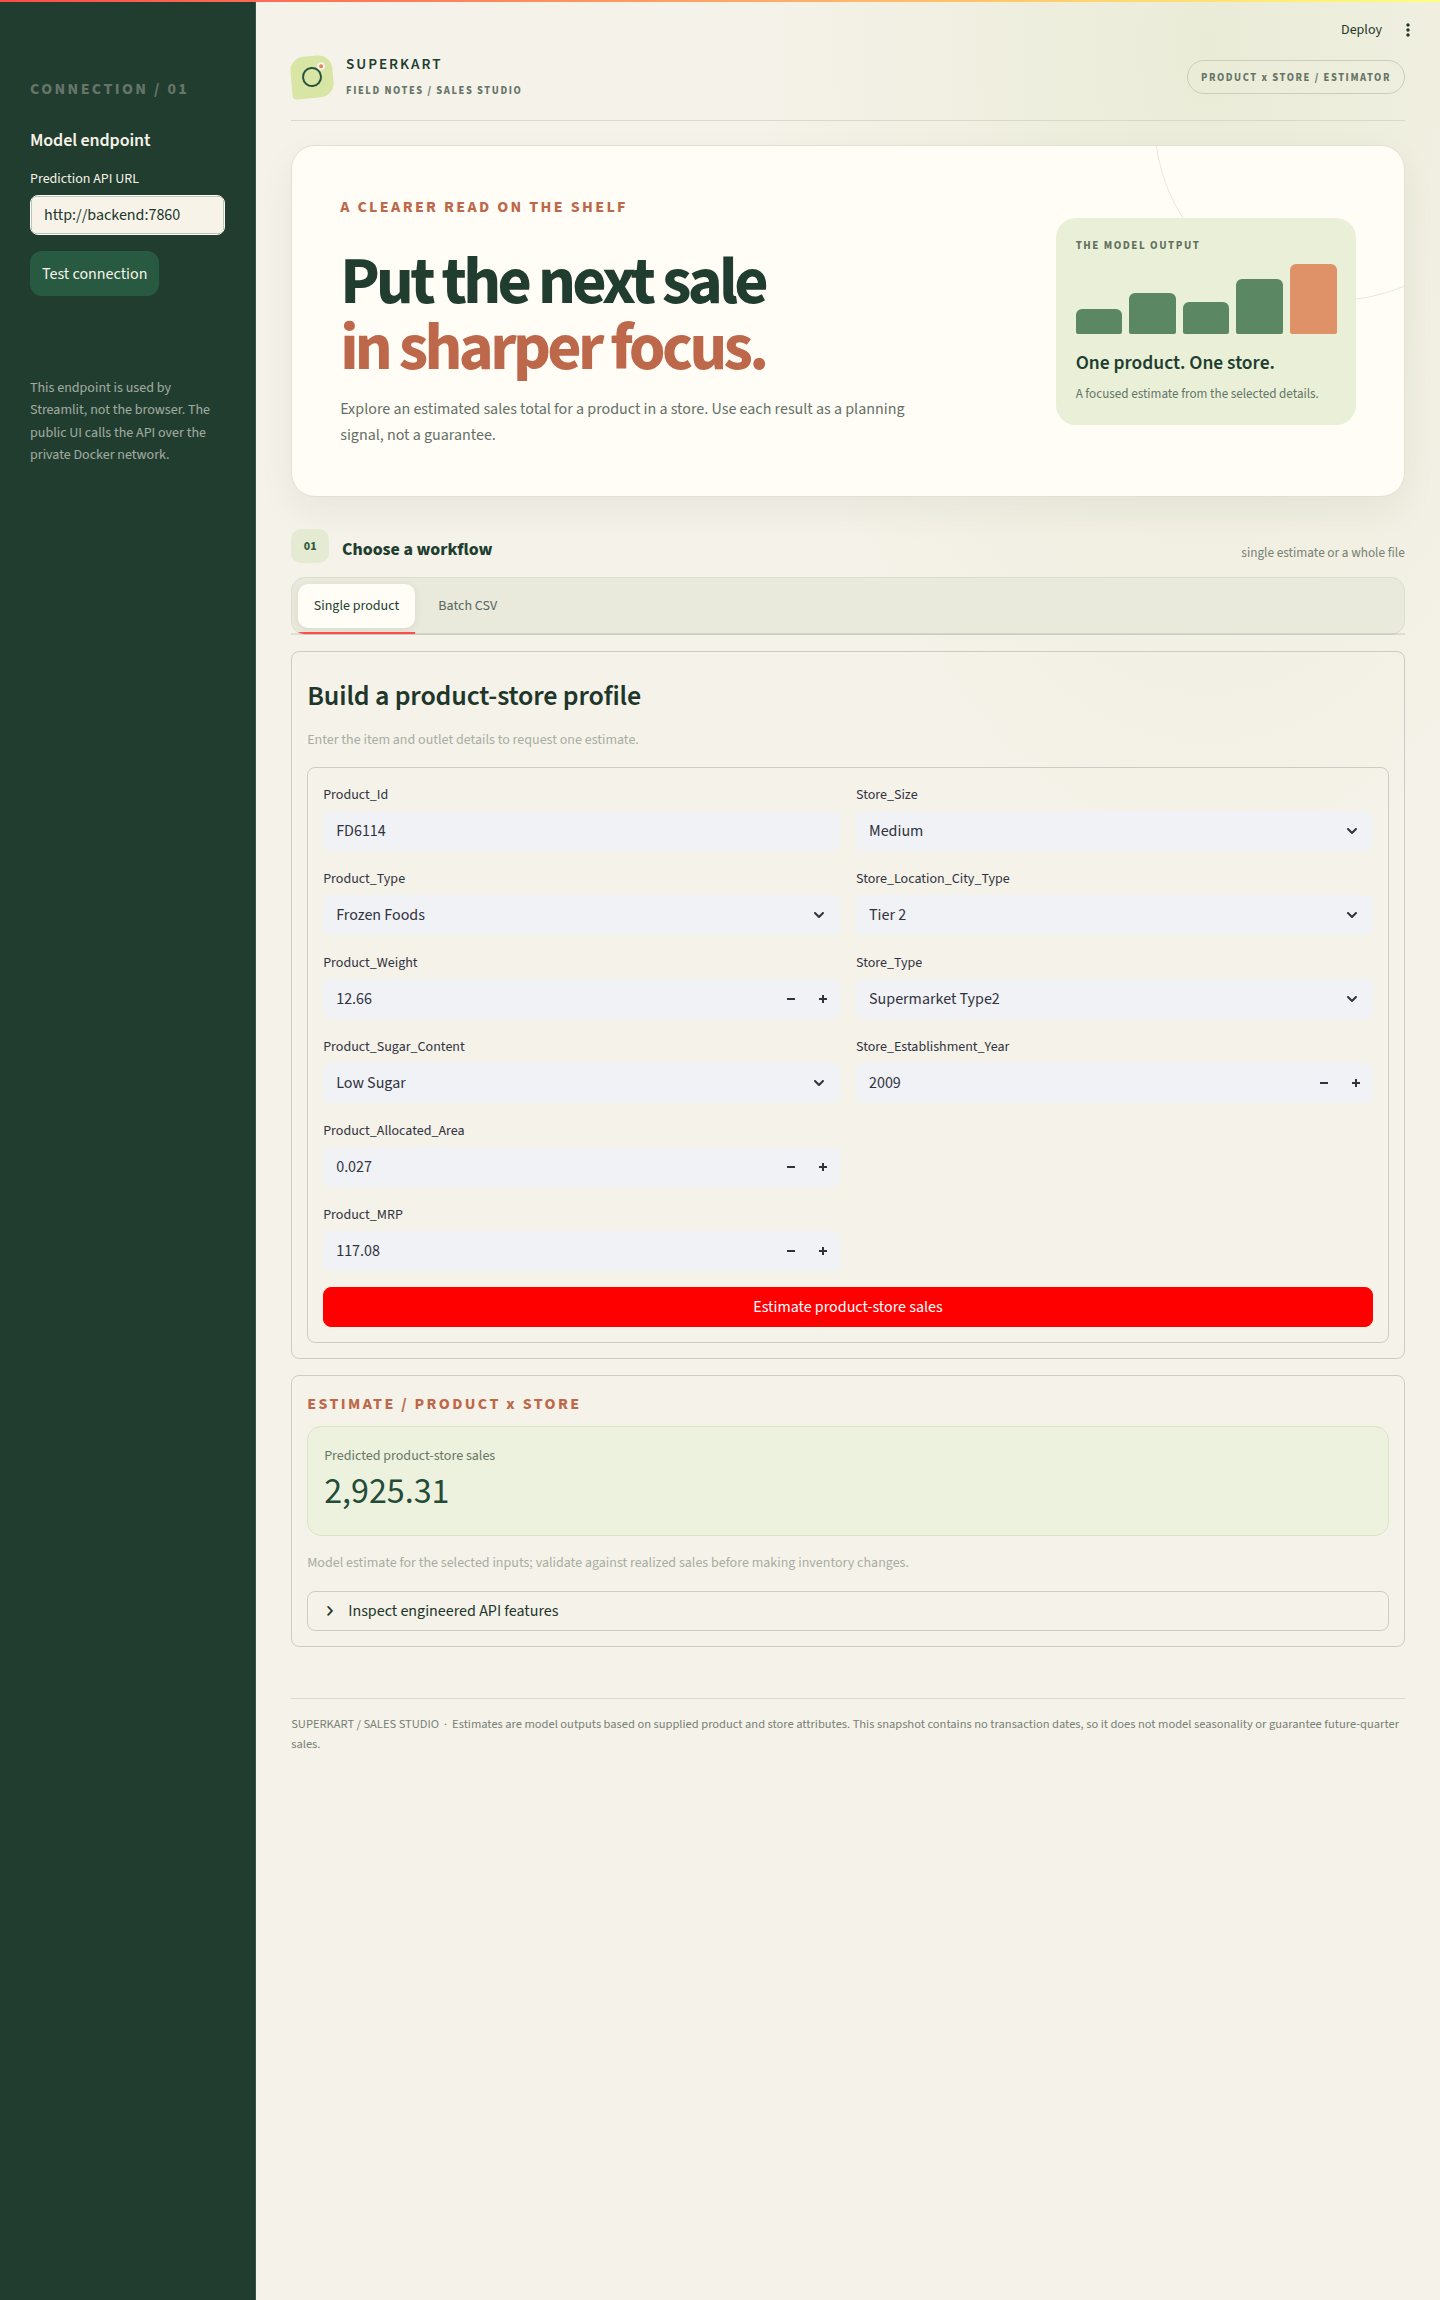


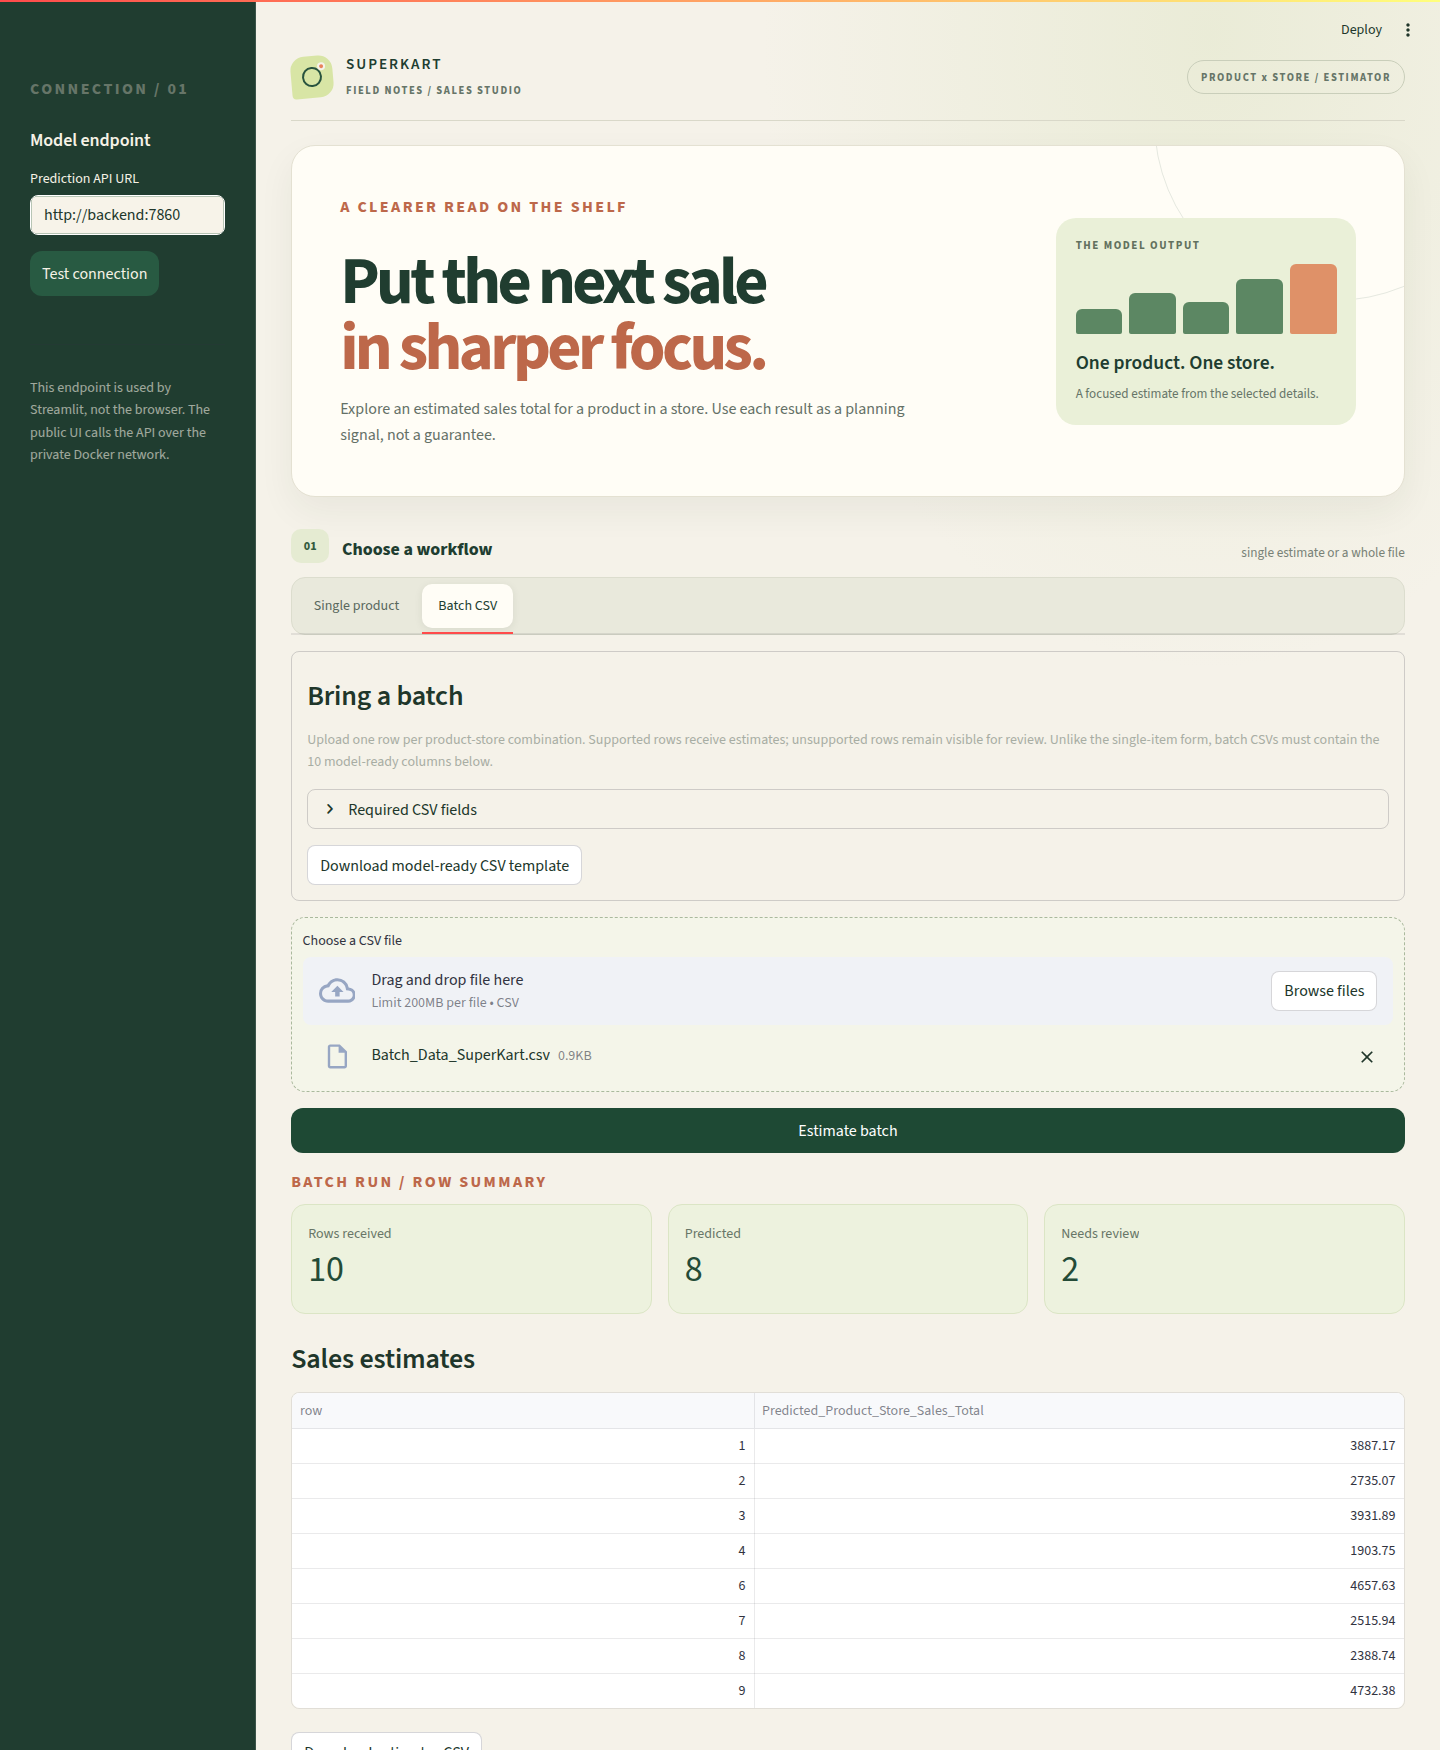

In [18]:
from IPython.display import HTML

for caption, screenshot_name in [
    ('Live single-product inference using an observed Frozen Foods profile; prediction 2,925.31.', 'public-single-prediction.png'),
    ('Live batch inference showing 10 received rows, 8 predictions, and 2 review rows in row-first order.', 'public-batch-inference.png'),
]:
    screenshot = ROOT / 'screenshots' / screenshot_name
    image = base64.b64encode(screenshot.read_bytes()).decode('ascii')
    display(HTML(f'<img alt="{caption}" src="data:image/png;base64,{image}" style="max-width:100%;height:auto">'))

## Limitations and further validation

- This dataset has no transaction dates or quarter labels. The model estimates product-store sales from supplied attributes; it does not learn seasonal or time-dependent forecasts.
- Product-type perishability is a documented two-group approximation. Product-level stocking decisions should be reviewed by business owners.
- Test metrics describe one random holdout split and do not establish future-period performance or performance on unseen stores.
- An unknown `Store_Type` is rejected instead of predicted. Retrain and revalidate before supporting new categories.
- Adjusted R² is a feature-count approximation included for context; its standard interpretation is not exact for tree ensembles.
